В данном блокноте я хочу разобраться именно с сигналом из данных, чтобы понять, что вообще происходит в событиях и какие признаки создавать для модели.
Пока мои первые предположения:
- Боты кликают с меньшим временным окном, работают длинными сериями
- Также ботов можно вычислить по их активности в течении суток 

Пока это только предположения, поэтому необходимо в первую очередь посмотреть на данные.

# Первый блок - это загрузка библиотек, проверка данных

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
train = pd.read_csv("data/train.csv", parse_dates=["cookie_created_at", "window_start_ts", "window_end_ts"])
test = pd.read_csv("data/test.csv", parse_dates=["cookie_created_at", "window_start_ts", "window_end_ts"])
events = pd.read_csv("data/events.csv.gz", parse_dates=["event_ts"])

После загрузки посмотрим размеры и базовую структуру данных. Это бывает полезно, так как иногда происходит так, что заявленные колонки не соответствуют ожиданиям.

In [3]:
print("train:", train.shape)
print("test:", test.shape)
print("events:", events.shape)

print("Train columns:", train.columns.tolist())
print("Test columns:", test.columns.tolist())
print("Events columns:", events.columns.tolist())

train: (11091, 5)
test: (4909, 4)
events: (328905, 14)
Train columns: ['cookie_id', 'cookie_created_at', 'window_start_ts', 'window_end_ts', 'target']
Test columns: ['cookie_id', 'cookie_created_at', 'window_start_ts', 'window_end_ts']
Events columns: ['cookie_id', 'event_ts', 'eid', 'event_name', 'platform', 'user_agent', 'item_id', 'item_category', 'item_location', 'seller_type', 'search_query', 'search_page', 'pointer_x', 'pointer_y']


Далее - посмотрим на идентификаторы

In [4]:
print("Повторяющиеся куки в трейне:", train["cookie_id"].duplicated().sum())
print("Повторяющиеся куки в тесте:", test["cookie_id"].duplicated().sum())

train_ids = set(train["cookie_id"])
test_ids = set(test["cookie_id"])
event_ids = set(events["cookie_id"])

print("Пересечения трейна и теста:", len(train_ids & test_ids))
print("Трейн куки без событий:", len(train_ids - event_ids))
print("Тест куки без событий:", len(test_ids - event_ids))
print("Куки событий не в трейне или тесте:", len(event_ids - train_ids - test_ids))

Повторяющиеся куки в трейне: 0
Повторяющиеся куки в тесте: 0
Пересечения трейна и теста: 0
Трейн куки без событий: 0
Тест куки без событий: 0
Куки событий не в трейне или тесте: 0


Далее посмотрим на целевую переменную

In [5]:
target_counts = train["target"].value_counts().sort_index()
target_share = train["target"].value_counts(normalize=True).sort_index()

print(target_counts)
print(target_share)

target
0    10192
1      899
Name: count, dtype: int64
target
0    0.918943
1    0.081057
Name: proportion, dtype: float64


Здесь вижу очень сильный дисбаланс классов. Из-за этого по целевой метрике придется очень тяжко, необходимо будет предсказывать как минимум 70% ботов не захватывая в это всё людей

Далее посмотрим на временные границы

In [6]:
print("Старт окна в трейне:", train["window_start_ts"].min(), "-", train["window_start_ts"].max())
print("Конец окна в трейне:", train["window_end_ts"].min(), "-", train["window_end_ts"].max())
print("Старт окна в тесте:", test["window_start_ts"].min(), "-", test["window_start_ts"].max())
print("Конец окна в тесте:", test["window_end_ts"].min(), "-", test["window_end_ts"].max())
print("События:", events["event_ts"].min(), "-", events["event_ts"].max())

Старт окна в трейне: 2026-04-06 00:00:00 - 2026-04-19 00:00:00
Конец окна в трейне: 2026-04-07 00:00:00 - 2026-04-20 00:00:00
Старт окна в тесте: 2026-04-20 00:00:00 - 2026-04-26 00:00:00
Конец окна в тесте: 2026-04-21 00:00:00 - 2026-04-27 00:00:00
События: 2026-04-06 00:02:57 - 2026-04-26 23:59:50


Т.к. объект классификации задается суточным наблюдением, нам необходимо использовать события, попавшие в соответствующее окно каждой куки

In [7]:
def events_in_window(events, meta):
    ev = events.merge(meta[["cookie_id", "window_start_ts", "window_end_ts"]], on="cookie_id", how="inner")
    ev = ev[(ev["event_ts"] >= ev["window_start_ts"]) & (ev["event_ts"] < ev["window_end_ts"])].copy()
    ev = ev.drop(columns=["window_start_ts", "window_end_ts"])
    return ev

ev_train = events_in_window(events, train)
ev_test = events_in_window(events, test)
events_window = pd.concat([ev_train, ev_test], ignore_index=True)

print("Событий трейн внутри окна:", len(ev_train))
print("Событий теста внутри окна:", len(ev_test))
print("Всего событий внутри окон:", len(events_window))
print("Событий вне окон:", len(events) - len(events_window))

Событий трейн внутри окна: 198436
Событий теста внутри окна: 89690
Всего событий внутри окон: 288126
Событий вне окон: 40779


Далее проверим наличие полных дубликатов уже среди событий, относящихся к окнам наблюдения

In [8]:
print("Полные дубликаты событий внутри окон:", events_window.duplicated().sum())

Полные дубликаты событий внутри окон: 4293


В обычной задачке я бы такое чистил, но здесь может скрываться какой-то интересный сигнал 

# Второй блок - базовый EDA

Посмотрим на стабильность таргета во времени

In [9]:
target_by_day = train.groupby("window_start_ts")["target"].agg(["count", "sum", "mean"])
target_by_day.columns = ["n_cookies", "n_bots", "bot_rate"]

target_by_day

,n_cookies,n_bots,bot_rate
window_start_ts,,,
2026-04-06,772,68,0.088083
2026-04-07,797,59,0.074028
2026-04-08,834,70,0.083933
2026-04-09,902,66,0.073171
2026-04-10,912,82,0.089912
2026-04-11,896,79,0.088170
2026-04-12,817,67,0.082007
2026-04-13,843,53,0.062871
2026-04-14,826,70,0.084746


Посмотрим на график количества объектов по дням

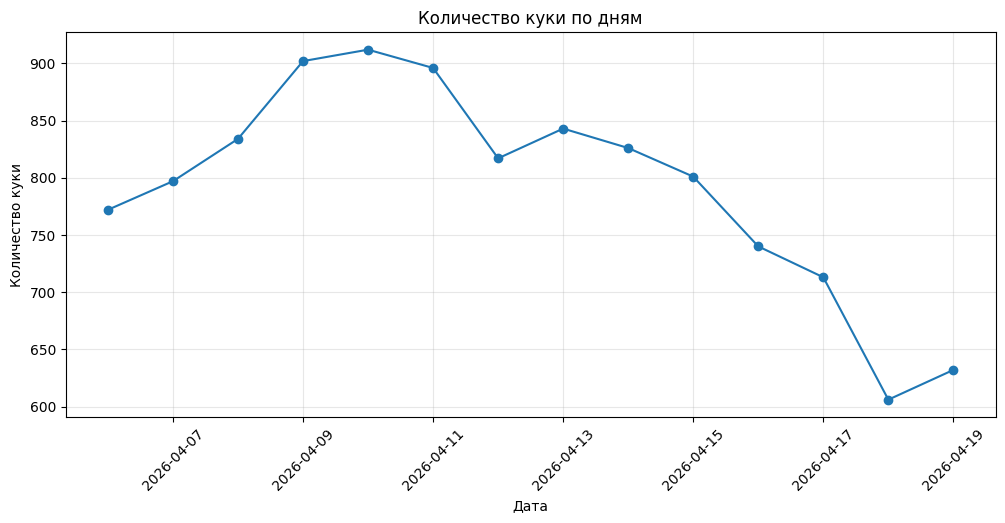

In [10]:
plt.figure(figsize=(12, 5))
plt.plot(target_by_day.index, target_by_day["n_cookies"], marker="o")
plt.xlabel("Дата")
plt.ylabel("Количество куки")
plt.title("Количество куки по дням")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.show()

Посмотрим на график доли ботов

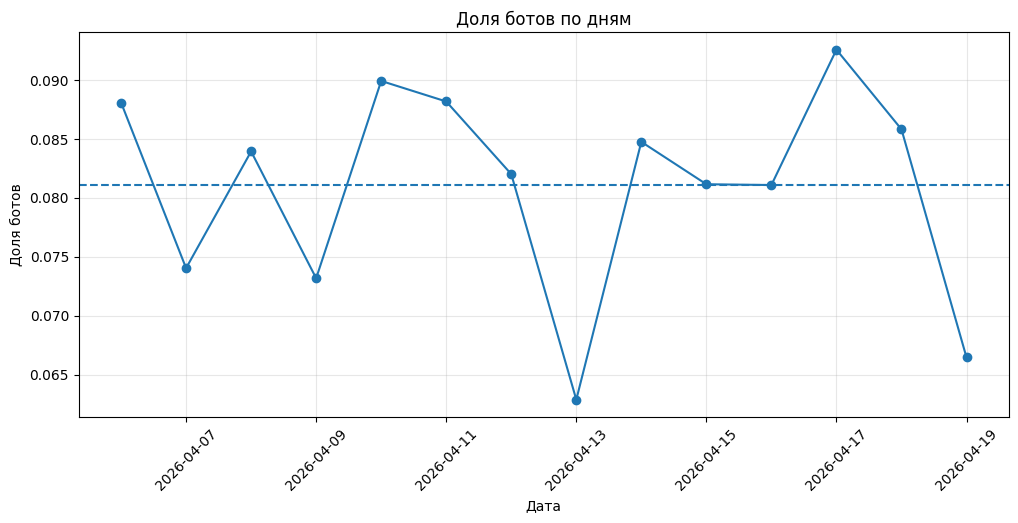

In [11]:
plt.figure(figsize=(12, 5))
plt.plot(target_by_day.index, target_by_day["bot_rate"], marker="o")
plt.axhline(train["target"].mean(), linestyle="--")
plt.xlabel("Дата")
plt.ylabel("Доля ботов")
plt.title("Доля ботов по дням")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.show()

Далее посмотрим на количество событий, совершённых каждой куки в пределах её окна наблюдения

In [12]:
events_per_cookie_train = ev_train.groupby("cookie_id").size().rename("n_events").reset_index()
events_per_cookie_train = train[["cookie_id", "target", "window_start_ts"]].merge(events_per_cookie_train, on="cookie_id", how="left")

events_per_cookie_train.groupby("target")["n_events"].describe(percentiles=[0.5, 0.75, 0.9, 0.95, 0.99])

,count,mean,std,min,50%,75%,90%,95%,99%,max
target,,,,,,,,,,
0,10192.0,16.869015,16.173297,1.0,12.0,22.0,37.0,50.0,79.00,140.0
1,899.0,29.484983,27.515182,1.0,20.0,38.0,67.2,88.0,134.04,169.0


И визуализируем

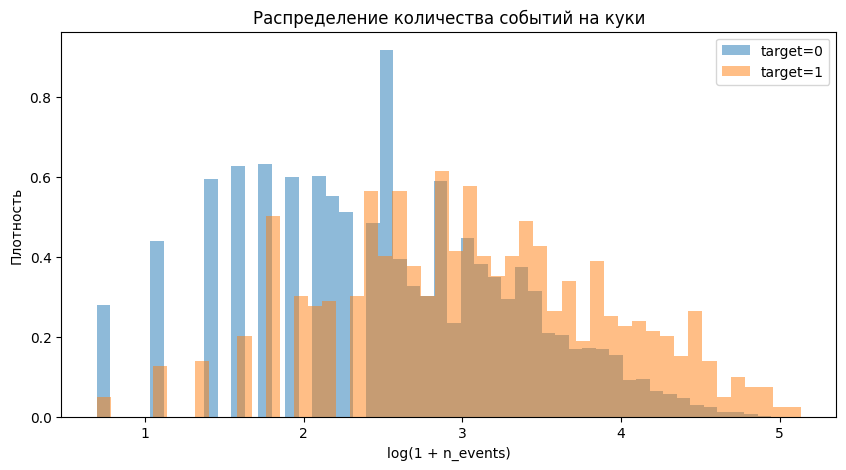

In [13]:
plt.figure(figsize=(10, 5))

for target in [0, 1]:
    values = np.log1p(events_per_cookie_train.loc[events_per_cookie_train["target"] == target, "n_events"])
    plt.hist(values, bins=50, alpha=0.5, density=True, label=f"target={target}")

plt.xlabel("log(1 + n_events)")
plt.ylabel("Плотность")
plt.title("Распределение количества событий на куки")
plt.legend()
plt.show()

Отдельно посмотрим, отличается ли повторяемость полностью идентичных событий у ботов и человеческого трафика

In [14]:
ev_train_duplicates = ev_train.copy()
ev_train_duplicates["is_duplicate"] = ev_train_duplicates.duplicated(keep=False)

duplicates_per_cookie = ev_train_duplicates.groupby("cookie_id")["is_duplicate"].agg(["sum", "mean"]).reset_index()
duplicates_per_cookie.columns = ["cookie_id", "n_duplicate_events", "duplicate_event_share"]

duplicates_train = train[["cookie_id", "target"]].merge(duplicates_per_cookie, on="cookie_id", how="left")

duplicates_train.groupby("target")[["n_duplicate_events", "duplicate_event_share"]].describe()

n_duplicate_events                                                \
                    count      mean       std  min  25%  50%  75%   max   
target                                                                    
0                 10192.0  0.500392  1.104846  0.0  0.0  0.0  0.0  12.0   
1                   899.0  0.894327  1.528118  0.0  0.0  0.0  2.0  10.0   

       duplicate_event_share                                                    
                       count      mean       std  min  25%  50%       75%  max  
target                                                                          
0                    10192.0  0.026723  0.072583  0.0  0.0  0.0  0.000000  1.0  
1                      899.0  0.028730  0.062839  0.0  0.0  0.0  0.043478  1.0

In [15]:
duplicates_train["has_duplicates"] = duplicates_train["n_duplicate_events"] > 0

duplicate_rate_by_target = duplicates_train.groupby("target")["has_duplicates"].mean()
duplicate_rate_by_target

target
0    0.203297
1    0.320356
Name: has_duplicates, dtype: float64

Здесь я уже вижу некоторые закономерности, из которых можно сделать выводы:
- Доля ботов по дням колеблется примерно от 6.3% до 9.3%, при этом явного временного тренда не наблюдается
- Количество объектов в последние дни трейна уменьшается, поэтому в дальнейшем стоит отдельно проверить устойчивость модели на нескольких временных разбиениях
- Количество событий отличается между классами: медиана составляет 12 событий для человеческого трафика и 20 для ботов, а среднее примерно 16.87 и 29.48 соответственно. Признак содержит сигнал, но распределения существенно пересекаются
- Хотя хотя бы одно дублирующееся событие встречается примерно у 20.3% человеческих куки и 32.0% ботов, средняя доля таких событий близка: около 2.67% и 2.87%. Поэтому абсолютное число дубликатов может частично объясняться большей общей активностью ботов

Далее рассмотрим состав событий внутри окон наблюдения

In [16]:
event_counts = events_window["event_name"].value_counts()
event_counts

event_name
item_view               108086
search_results_view      89798
photo_swipe              33084
favorite_add             17296
seller_page_view         15542
contact_phone_show       10288
login                     5661
contact_chat_open         5548
contact_message_sent      2823
Name: count, dtype: int64

Сравним структуру событий между двумя классами

In [17]:
train_events = ev_train.merge(train[["cookie_id", "target"]], on="cookie_id", how="left")

event_target_counts = train_events.groupby(["event_name", "target"]).size().unstack(fill_value=0)
event_target_counts.columns = ["human_events", "bot_events"]

event_target_counts["human_share"] = event_target_counts["human_events"] / event_target_counts["human_events"].sum()
event_target_counts["bot_share"] = event_target_counts["bot_events"] / event_target_counts["bot_events"].sum()

event_target_counts.sort_values("bot_share", ascending=False)

,human_events,bot_events,human_share,bot_share
event_name,,,,
item_view,62770,11568,0.365093,0.436413
search_results_view,52399,9318,0.304771,0.351530
photo_swipe,21091,1860,0.122673,0.070170
seller_page_view,9125,1563,0.053074,0.058966
favorite_add,11317,720,0.065824,0.027163
contact_phone_show,6361,685,0.036998,0.025842
contact_chat_open,3404,376,0.019799,0.014185
contact_message_sent,1769,210,0.010289,0.007922
login,3693,207,0.021480,0.007809


Помимо общего количества событий полезно посмотреть, какая доля куки каждого класса вообще совершала определённый тип действия

In [18]:
cookie_event_presence = train_events[["cookie_id", "target", "event_name"]].drop_duplicates()
cookie_event_presence = cookie_event_presence.groupby(["event_name", "target"]).size().unstack(fill_value=0)

n_humans = (train["target"] == 0).sum()
n_bots = (train["target"] == 1).sum()

cookie_event_presence["human_cookie_share"] = cookie_event_presence[0] / n_humans
cookie_event_presence["bot_cookie_share"] = cookie_event_presence[1] / n_bots
cookie_event_presence["share_diff"] = cookie_event_presence["bot_cookie_share"] - cookie_event_presence["human_cookie_share"]

cookie_event_presence.sort_values("share_diff", ascending=False)

target,0,1,human_cookie_share,bot_cookie_share,share_diff
event_name,,,,,
seller_page_view,5043,608,0.494800,0.676307,0.181507
item_view,9479,883,0.930043,0.982202,0.052159
search_results_view,9308,862,0.913265,0.958843,0.045578
contact_message_sent,1393,156,0.136676,0.173526,0.036850
contact_phone_show,3548,346,0.348116,0.384872,0.036756
contact_chat_open,2330,229,0.228611,0.254727,0.026117
photo_swipe,7443,658,0.730279,0.731924,0.001646
login,2740,173,0.268838,0.192436,-0.076402
favorite_add,5582,403,0.547684,0.448276,-0.099409


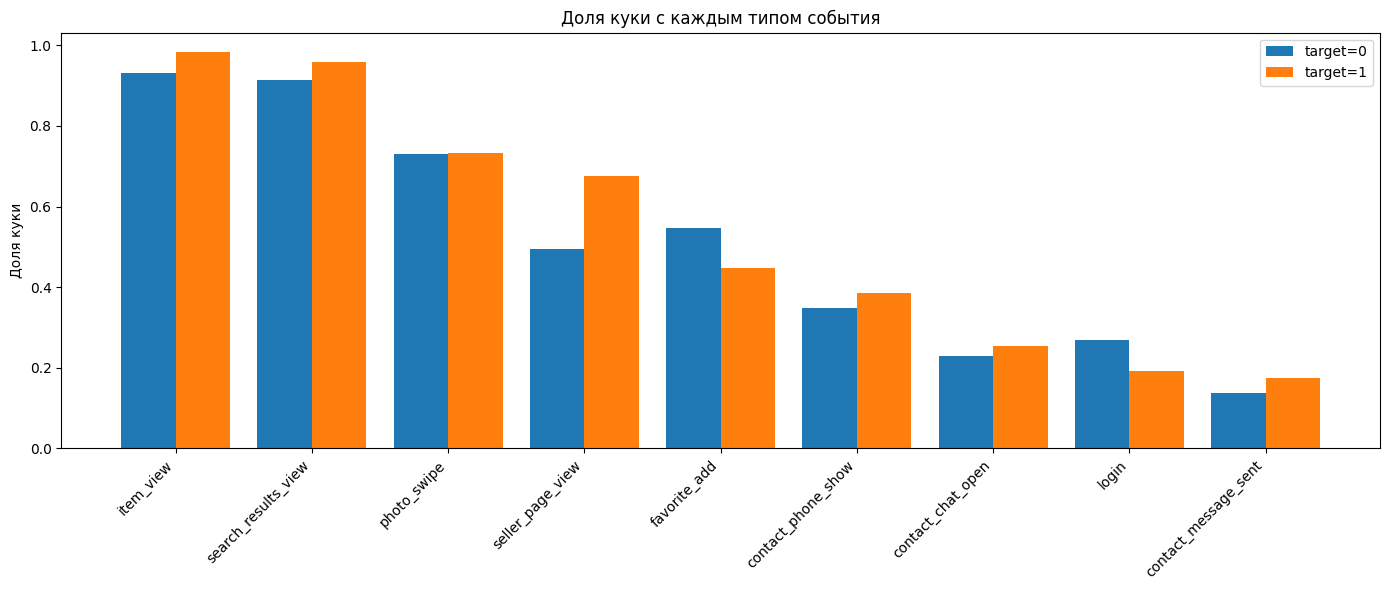

In [19]:
event_presence_plot = cookie_event_presence.sort_values("bot_cookie_share", ascending=False)

x = np.arange(len(event_presence_plot))

plt.figure(figsize=(14, 6))
plt.bar(x - 0.2, event_presence_plot["human_cookie_share"], width=0.4, label="target=0")
plt.bar(x + 0.2, event_presence_plot["bot_cookie_share"], width=0.4, label="target=1")
plt.xticks(x, event_presence_plot.index, rotation=45, ha="right")
plt.ylabel("Доля куки")
plt.title("Доля куки с каждым типом события")
plt.legend()
plt.tight_layout()
plt.show()

Далее следующий блок

# Третий блок - временное поведение

Одно из основных предположений состоит в том, что автоматизированный трафик может отличаться от человеческого характером временной активности. А для проверки этого рассмотрим интервалы между последовательными событиями каждой куки

Сначала проведем небольшую подготовку

In [20]:
ev_time = ev_train[["cookie_id", "event_ts"]].copy()
ev_time = ev_time.sort_values(["cookie_id", "event_ts"])

ev_time["gap_sec"] = ev_time.groupby("cookie_id")["event_ts"].diff().dt.total_seconds()

ev_time["gap_eq_0"] = np.where(ev_time["gap_sec"].notna(), ev_time["gap_sec"] == 0, np.nan)
ev_time["gap_le_1"] = np.where(ev_time["gap_sec"].notna(), ev_time["gap_sec"] <= 1, np.nan)
ev_time["gap_le_5"] = np.where(ev_time["gap_sec"].notna(), ev_time["gap_sec"] <= 5, np.nan)
ev_time["gap_le_10"] = np.where(ev_time["gap_sec"].notna(), ev_time["gap_sec"] <= 10, np.nan)
ev_time["gap_le_30"] = np.where(ev_time["gap_sec"].notna(), ev_time["gap_sec"] <= 30, np.nan)

Далее собираем временные характеристики на уровне одной куки

In [21]:
time_features = ev_time.groupby("cookie_id").agg(n_events=("event_ts", "size"), first_event_ts=("event_ts", "min"), last_event_ts=("event_ts", "max"), n_unique_timestamps=("event_ts", "nunique"), mean_gap_sec=("gap_sec", "mean"), median_gap_sec=("gap_sec", "median"), std_gap_sec=("gap_sec", "std"), min_gap_sec=("gap_sec", "min"), max_gap_sec=("gap_sec", "max"), share_gap_eq_0=("gap_eq_0", "mean"), share_gap_le_1=("gap_le_1", "mean"), share_gap_le_5=("gap_le_5", "mean"), share_gap_le_10=("gap_le_10", "mean"), share_gap_le_30=("gap_le_30", "mean")).reset_index()

time_features["active_span_sec"] = (time_features["last_event_ts"] - time_features["first_event_ts"]).dt.total_seconds()
time_features["unique_timestamp_ratio"] = time_features["n_unique_timestamps"] / time_features["n_events"]
time_features["events_per_active_hour"] = np.where(time_features["active_span_sec"] > 0, (time_features["n_events"] - 1) / (time_features["active_span_sec"] / 3600), np.nan)

time_features_train = train[["cookie_id", "target"]].merge(time_features, on="cookie_id", how="left")

In [22]:
single_event_rate = time_features_train.groupby("target")["n_events"].apply(lambda x: (x == 1).mean())
single_event_rate

target
0    0.023842
1    0.004449
Name: n_events, dtype: float64

Теперь посмотрим основные значения

In [23]:
time_cols = ["n_events", "active_span_sec", "mean_gap_sec", "median_gap_sec", "std_gap_sec", "min_gap_sec", "max_gap_sec", "events_per_active_hour", "share_gap_eq_0", "share_gap_le_1", "share_gap_le_5", "share_gap_le_10", "share_gap_le_30", "unique_timestamp_ratio"]

time_medians = time_features_train.groupby("target")[time_cols].median().T
time_medians.columns = ["human_median", "bot_median"]

time_medians

,human_median,bot_median
n_events,12.000000,20.000000
active_span_sec,8326.500000,9092.000000
mean_gap_sec,657.294118,425.407407
median_gap_sec,59.000000,25.000000
std_gap_sec,1732.919959,1368.461303
min_gap_sec,5.000000,3.000000
max_gap_sec,5893.000000,6035.000000
events_per_active_hour,5.465956,8.457582
share_gap_eq_0,0.000000,0.000000
share_gap_le_1,0.000000,0.000000


И отдельно средние, потому что некоторые временные признаки сильно скошены

In [24]:
time_means = time_features_train.groupby("target")[time_cols].mean().T
time_means.columns = ["human_mean", "bot_mean"]

time_means

,human_mean,bot_mean
n_events,16.869015,29.484983
active_span_sec,11621.668662,12082.845384
mean_gap_sec,839.432893,562.149225
median_gap_sec,219.330083,99.973743
std_gap_sec,1642.118535,1326.165772
min_gap_sec,59.186250,36.806704
max_gap_sec,4963.744497,5066.964246
events_per_active_hour,25.869919,37.809665
share_gap_eq_0,0.022183,0.017789
share_gap_le_1,0.033306,0.022726


Далее поработаем с графиками, первый из них будет про длительную активность куки внутри суток, второй про медианный интервал между действиями, а третий - доля очень быстрых переходов

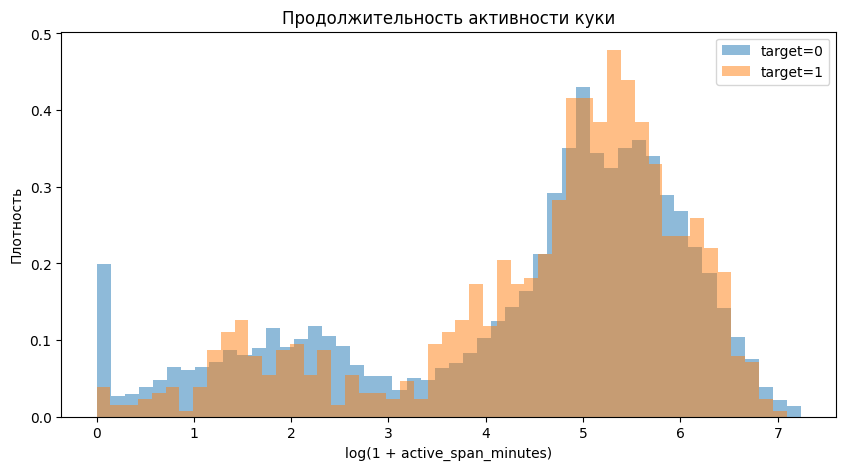

In [25]:
plt.figure(figsize=(10, 5))

for target in [0, 1]:
    values = np.log1p(time_features_train.loc[time_features_train["target"] == target, "active_span_sec"] / 60)
    plt.hist(values, bins=50, alpha=0.5, density=True, label=f"target={target}")

plt.xlabel("log(1 + active_span_minutes)")
plt.ylabel("Плотность")
plt.title("Продолжительность активности куки")
plt.legend()
plt.show()

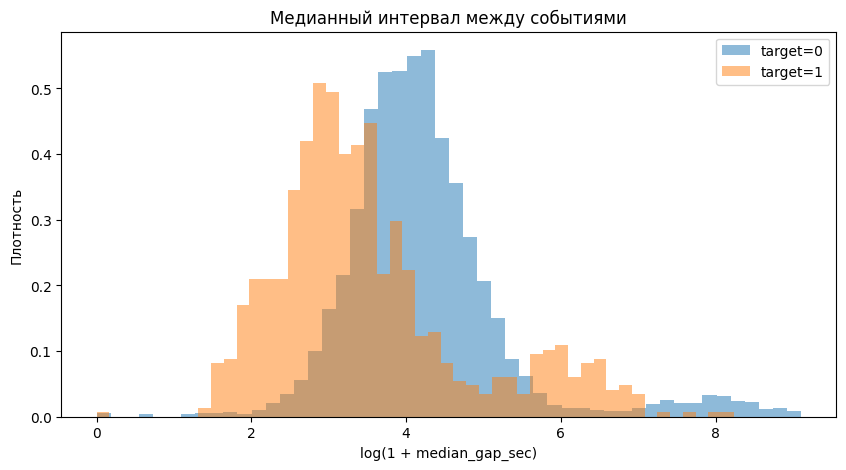

In [26]:
plt.figure(figsize=(10, 5))

for target in [0, 1]:
    values = np.log1p(time_features_train.loc[time_features_train["target"] == target, "median_gap_sec"].dropna())
    plt.hist(values, bins=50, alpha=0.5, density=True, label=f"target={target}")

plt.xlabel("log(1 + median_gap_sec)")
plt.ylabel("Плотность")
plt.title("Медианный интервал между событиями")
plt.legend()
plt.show()

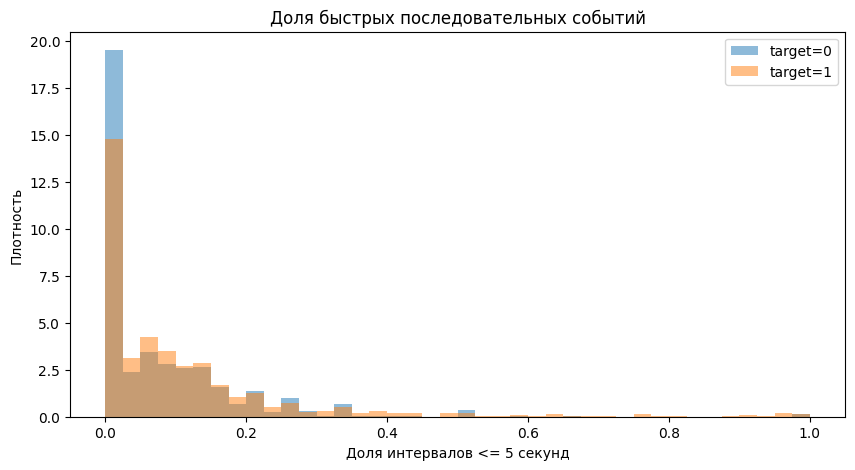

In [27]:
plt.figure(figsize=(10, 5))

for target in [0, 1]:
    values = time_features_train.loc[time_features_train["target"] == target, "share_gap_le_5"].dropna()
    plt.hist(values, bins=40, alpha=0.5, density=True, label=f"target={target}")

plt.xlabel("Доля интервалов <= 5 секунд")
plt.ylabel("Плотность")
plt.title("Доля быстрых последовательных событий")
plt.legend()
plt.show()

Далее проверим насколько часто несколько событий имеют одну и ту же секунду

In [28]:
same_timestamp_rate = time_features_train.groupby("target")["share_gap_eq_0"].describe()
same_timestamp_rate

,count,mean,std,min,25%,50%,75%,max
target,,,,,,,,
0,9949.0,0.022183,0.060205,0.0,0.0,0.0,0.019231,1.0
1,895.0,0.017789,0.045841,0.0,0.0,0.0,0.023810,1.0


Здесь получаем довольно содержательный сигнал.
- active_span_sec почти не разделяет классы: медиана около 2.3 ч у людей и 2.5 ч у ботов. То есть боты не обязательно сидят в окне дольше
- Зато они работают заметно плотнее
- share_gap_le_30 выглядит особенно хорошо: медиана 0.30 против 0.60
- share_gap_le_10: 0.097 против 0.182
- Нулевые интервалы почти бесполезны
- unique_timestamp_ratio примерно 1 у обоих классов - почти бессмысленно

То есть моя первая гипотеза подтверждает, но немного в другом смысле. Бот за сопоставимый период совершает действия чаще и с меньшими паузами

Далее перейдем к следующему блоку

# Четвертый блок - как бот исследует объявления и поисковую выдачу

Начнём с поведения по предметам

In [29]:
item_features = ev_train.groupby("cookie_id").agg(item_nunique=("item_id", "nunique"), category_nunique=("item_category", "nunique"), location_nunique=("item_location", "nunique"), seller_type_nunique=("seller_type", "nunique")).reset_index()

item_view_events = ev_train[ev_train["event_name"] == "item_view"].copy()

item_view_features = item_view_events.groupby("cookie_id").agg(item_view_count=("item_id", "size"), item_view_nunique=("item_id", "nunique")).reset_index()

item_features = item_features.merge(item_view_features, on="cookie_id", how="left")
item_features = item_features.fillna(0)

item_features["item_view_repeat_count"] = item_features["item_view_count"] - item_features["item_view_nunique"]
item_features["item_view_unique_ratio"] = np.where(item_features["item_view_count"] > 0, item_features["item_view_nunique"] / item_features["item_view_count"], np.nan)

item_features_train = train[["cookie_id", "target"]].merge(item_features, on="cookie_id", how="left")

Посмотрим медианы

In [30]:
item_cols = ["item_nunique", "category_nunique", "location_nunique", "seller_type_nunique", "item_view_count", "item_view_nunique", "item_view_repeat_count", "item_view_unique_ratio"]

item_medians = item_features_train.groupby("target")[item_cols].median().T
item_medians.columns = ["human_median", "bot_median"]

item_medians

,human_median,bot_median
item_nunique,6.0,10.000000
category_nunique,2.0,2.000000
location_nunique,5.0,8.000000
seller_type_nunique,2.0,2.000000
item_view_count,4.0,8.000000
item_view_nunique,4.0,7.000000
item_view_repeat_count,0.0,1.000000
item_view_unique_ratio,1.0,0.866667


И средние

In [31]:
item_means = item_features_train.groupby("target")[item_cols].mean().T
item_means.columns = ["human_mean", "bot_mean"]

item_means

,human_mean,bot_mean
item_nunique,8.917190,13.779755
category_nunique,2.281201,1.787542
location_nunique,5.881868,9.789766
seller_type_nunique,1.757064,1.912125
item_view_count,6.158752,12.867631
item_view_nunique,5.304749,9.979978
item_view_repeat_count,0.854003,2.887653
item_view_unique_ratio,0.886086,0.851764


Отдельно посмотрим на отношение уникальных объявлений к числу просмотров

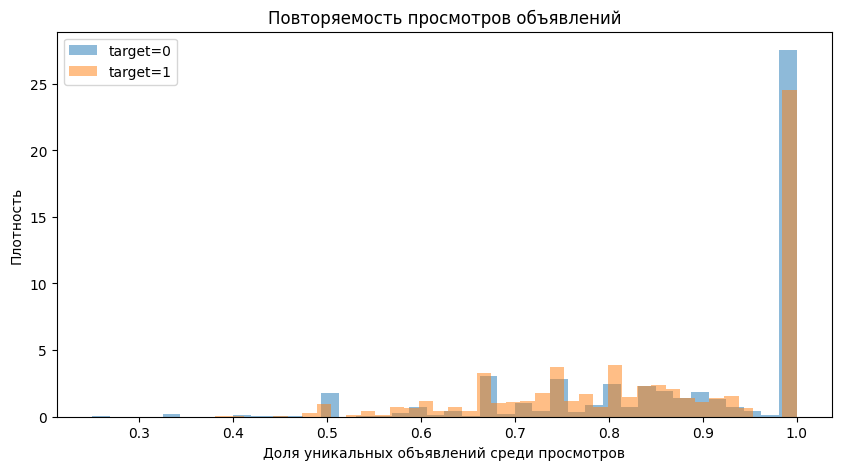

In [32]:
plt.figure(figsize=(10, 5))

for target in [0, 1]:
    values = item_features_train.loc[item_features_train["target"] == target, "item_view_unique_ratio"].dropna()
    plt.hist(values, bins=40, alpha=0.5, density=True, label=f"target={target}")

plt.xlabel("Доля уникальных объявлений среди просмотров")
plt.ylabel("Плотность")
plt.title("Повторяемость просмотров объявлений")
plt.legend()
plt.show()

И число уникальных объявлений

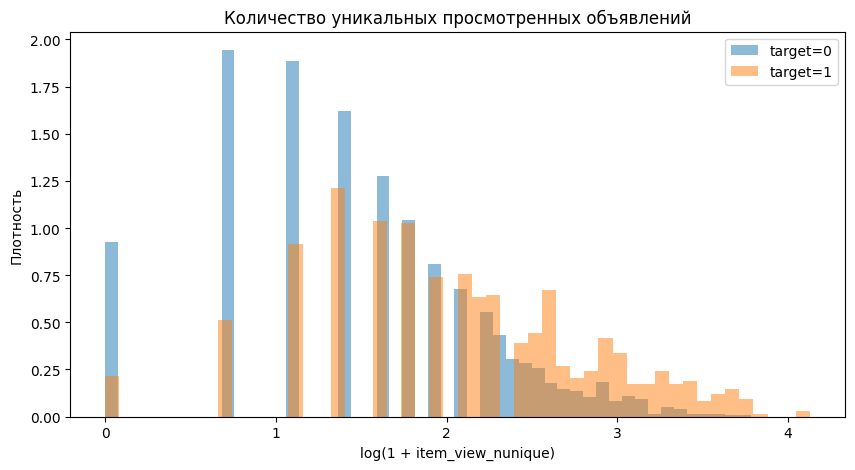

In [33]:
plt.figure(figsize=(10, 5))

for target in [0, 1]:
    values = np.log1p(item_features_train.loc[item_features_train["target"] == target, "item_view_nunique"])
    plt.hist(values, bins=50, alpha=0.5, density=True, label=f"target={target}")

plt.xlabel("log(1 + item_view_nunique)")
plt.ylabel("Плотность")
plt.title("Количество уникальных просмотренных объявлений")
plt.legend()
plt.show()

Далее перейдем к поиску

In [34]:
search_events = ev_train[ev_train["event_name"] == "search_results_view"].copy()

search_features = search_events.groupby("cookie_id").agg(search_count=("event_name", "size"), search_query_nunique=("search_query", "nunique"), search_page_mean=("search_page", "mean"), search_page_median=("search_page", "median"), search_page_max=("search_page", "max"), search_page_nunique=("search_page", "nunique")).reset_index()

search_features_train = train[["cookie_id", "target"]].merge(search_features, on="cookie_id", how="left")
search_features_train = search_features_train.fillna(0)

Медианы

In [35]:
search_cols = ["search_count", "search_query_nunique", "search_page_mean", "search_page_median", "search_page_max", "search_page_nunique"]

search_medians = search_features_train.groupby("target")[search_cols].median().T
search_medians.columns = ["human_median", "bot_median"]

search_medians

,human_median,bot_median
search_count,4.0,7.000000
search_query_nunique,3.0,4.000000
search_page_mean,2.0,3.071429
search_page_median,2.0,2.500000
search_page_max,3.0,7.000000
search_page_nunique,2.0,4.000000


И средние

In [36]:
search_means = search_features_train.groupby("target")[search_cols].mean().T
search_means.columns = ["human_mean", "bot_mean"]

search_means

,human_mean,bot_mean
search_count,5.141189,10.364850
search_query_nunique,3.789835,4.758621
search_page_mean,2.114041,3.441757
search_page_median,1.816670,2.773081
search_page_max,4.032673,8.916574
search_page_nunique,2.627060,4.982202


Далее посмотрим, как часто куки уходит дальше первой страницы и насколько глубоко

In [37]:
search_events["page_gt_1"] = search_events["search_page"] > 1
search_events["page_gt_3"] = search_events["search_page"] > 3
search_events["page_gt_5"] = search_events["search_page"] > 5

search_depth = search_events.groupby("cookie_id").agg(share_page_gt_1=("page_gt_1", "mean"), share_page_gt_3=("page_gt_3", "mean"), share_page_gt_5=("page_gt_5", "mean")).reset_index()

search_depth_train = train[["cookie_id", "target"]].merge(search_depth, on="cookie_id", how="left")
search_depth_train = search_depth_train.fillna(0)

search_depth_train.groupby("target")[["share_page_gt_1", "share_page_gt_3", "share_page_gt_5"]].mean().T

target,0,1
share_page_gt_1,0.496489,0.654994
share_page_gt_3,0.163951,0.327202
share_page_gt_5,0.059010,0.174797


И визуализируем максимально достигнутую страницу

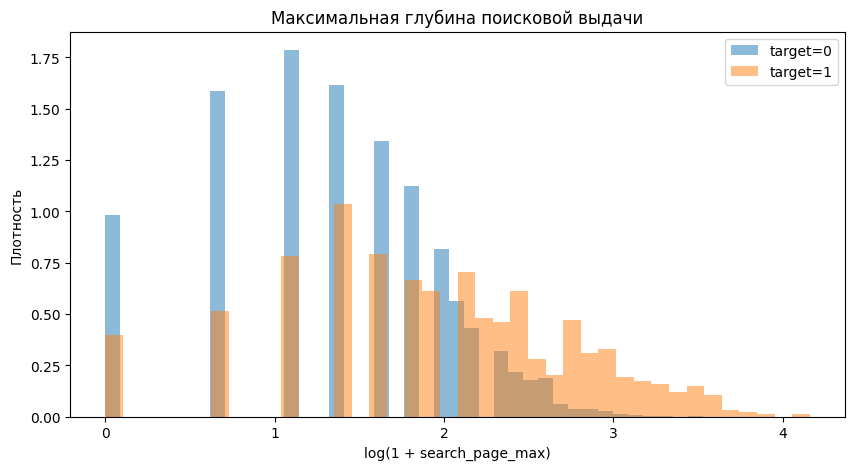

In [38]:
plt.figure(figsize=(10, 5))

for target in [0, 1]:
    values = np.log1p(search_features_train.loc[search_features_train["target"] == target, "search_page_max"])
    plt.hist(values, bins=40, alpha=0.5, density=True, label=f"target={target}")

plt.xlabel("log(1 + search_page_max)")
plt.ylabel("Плотность")
plt.title("Максимальная глубина поисковой выдачи")
plt.legend()
plt.show()

Здесь получил очень интересный паттерн поведения ботов. По объявлениям боты смотрят больше объектов: медиана item_view_count 8 против 4, уникальных просмотренных объявлений 7 против 4. При этом item_view_unique_ratio у ботов ниже (0.867 против 1.0 по медиане), а повторных просмотров больше.

Очень интересен location_nunique: 8 против 5 по медиане и 9.79 против 5.88 по среднему. При этом разнообразие категорий не растёт: медиана одинаковая, а среднее у ботов даже ниже. Получается довольно характерная картина: бот может работать внутри ограниченного набора категорий, но проходить существенно больше географических локаций

Самый сильный сигнал этого блока пока выглядит как глубина поиска. Медианный search_page_max 3-7, а средний 4.03 - 8.92

И особенно хорошо выглядят нормированные признаки: на страницы глубже 5-й уходит около 17.5% поисковых событий ботов против 5.9% у людей

Ещё одно важное наблюдение: search_count увеличивается примерно вдвое, а search_query_nunique растёт намного слабее. Значит, боты чаще продолжают работать с одним и тем же запросом, вероятно, листая выдачу дальше. Это стоит отдельно проверить.

Дополнительно посмотрим, насколько интенсивно куки используют одни и те же поисковые запросы

In [39]:
search_behavior = search_events.groupby("cookie_id").agg(search_count=("event_name", "size"), search_query_nunique=("search_query", "nunique")).reset_index()

search_behavior["searches_per_query"] = np.where(search_behavior["search_query_nunique"] > 0, search_behavior["search_count"] / search_behavior["search_query_nunique"], np.nan)

search_behavior_train = train[["cookie_id", "target"]].merge(search_behavior, on="cookie_id", how="left")

search_behavior_train.groupby("target")["searches_per_query"].describe(percentiles=[0.5, 0.75, 0.9, 0.95, 0.99])

,count,mean,std,min,50%,75%,90%,95%,99%,max
target,,,,,,,,,,
0,9308.0,1.279592,0.428823,1.0,1.0,1.444444,1.833333,2.000000,3.0000,7.5
1,862.0,1.934540,1.155230,1.0,1.5,2.282468,3.333333,4.414015,6.2225,8.0


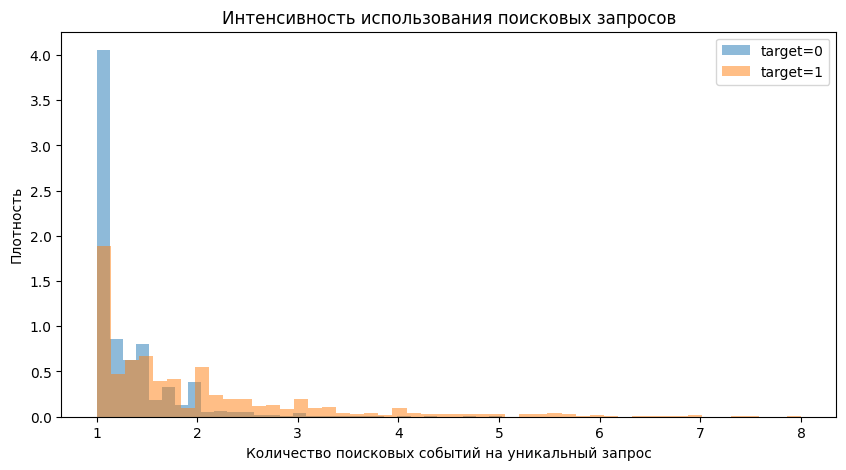

In [40]:
plt.figure(figsize=(10, 5))

for target in [0, 1]:
    values = search_behavior_train.loc[search_behavior_train["target"] == target, "searches_per_query"].dropna()
    plt.hist(values, bins=50, alpha=0.5, density=True, label=f"target={target}")

plt.xlabel("Количество поисковых событий на уникальный запрос")
plt.ylabel("Плотность")
plt.title("Интенсивность использования поисковых запросов")
plt.legend()
plt.show()

Посмотрим далее, сколько разных страниц выдачи куки реально проходит

In [41]:
query_page = search_events.dropna(subset=["search_query", "search_page"]).copy()

query_page_unique = query_page.groupby("cookie_id").apply(lambda x: x[["search_query", "search_page"]].drop_duplicates().shape[0], include_groups=False).rename("query_page_nunique").reset_index()

search_behavior_train = search_behavior_train.merge(query_page_unique, on="cookie_id", how="left")
search_behavior_train["query_page_nunique"] = search_behavior_train["query_page_nunique"].fillna(0)
search_behavior_train["unique_query_page_ratio"] = np.where(search_behavior_train["search_count"] > 0, search_behavior_train["query_page_nunique"] / search_behavior_train["search_count"], np.nan)

search_behavior_train.groupby("target")[["query_page_nunique", "unique_query_page_ratio"]].mean().T

target,0,1
query_page_nunique,4.654141,8.549499
unique_query_page_ratio,0.941476,0.891806


И ещё один хороший показатель, максимальное число различных страниц для одного и того же запроса

In [42]:
pages_per_query = search_events.dropna(subset=["search_query", "search_page"]).drop_duplicates(["cookie_id", "search_query", "search_page"]).groupby(["cookie_id", "search_query"]).size().rename("pages_for_query").reset_index()

pages_per_query_cookie = pages_per_query.groupby("cookie_id")["pages_for_query"].agg(["mean", "max"]).reset_index()
pages_per_query_cookie.columns = ["cookie_id", "pages_per_query_mean", "pages_per_query_max"]

pages_per_query_train = train[["cookie_id", "target"]].merge(pages_per_query_cookie, on="cookie_id", how="left")

pages_per_query_train.groupby("target")[["pages_per_query_mean", "pages_per_query_max"]].median().T

target,0,1
pages_per_query_mean,1.0,1.4
pages_per_query_max,1.0,2.0


Гипотеза в целом хорошо подтверждается.
У людей медиана searches_per_query = 1, у ботов 1.5; среднее 1.28 против 1.93. То есть бот действительно чаще продолжает работу с уже использованным запросом, а не просто генерирует больше разных запросов.

# Пятый блок - платформа и User-Agent

Далее рассмотрим технические характеристики трафика

In [43]:
tech_events = ev_train[["cookie_id", "event_ts", "platform", "user_agent"]].copy()

print(tech_events["platform"].value_counts(dropna=False))

platform
desktop    27855
Web        27470
WEB        27431
web        27251
ANDROID    26209
Android    25893
android    25889
IOS         2634
iOS         2626
iphone      2602
ios         2576
Name: count, dtype: int64


In [44]:
tech_events["platform_norm"] = tech_events["platform"].astype("string").str.strip().str.lower()

tech_events["platform_norm"].value_counts(dropna=False)

platform_norm
web        82152
android    77991
desktop    27855
ios         7836
iphone      2602
Name: count, dtype: int64[pyarrow]

Посмотрим распределение платформ на уровне событий

In [45]:
tech_events_target = tech_events.merge(train[["cookie_id", "target"]], on="cookie_id", how="left")

platform_event_share = pd.crosstab(tech_events_target["platform_norm"], tech_events_target["target"], normalize="columns")
platform_event_share.columns = ["human_share", "bot_share"]

platform_event_share.sort_values("bot_share", ascending=False)

,human_share,bot_share
platform_norm,,
web,0.392104,0.556004
android,0.417521,0.234165
desktop,0.132880,0.188969
ios,0.043169,0.015619
iphone,0.014326,0.005244


И на уровне куки

In [46]:
cookie_platform = tech_events_target.dropna(subset=["platform_norm"]).drop_duplicates(["cookie_id", "target", "platform_norm"])
cookie_platform_share = cookie_platform.groupby(["platform_norm", "target"]).size().unstack(fill_value=0)

cookie_platform_share["human_cookie_share"] = cookie_platform_share[0] / n_humans
cookie_platform_share["bot_cookie_share"] = cookie_platform_share[1] / n_bots
cookie_platform_share["share_diff"] = cookie_platform_share["bot_cookie_share"] - cookie_platform_share["human_cookie_share"]

cookie_platform_share.sort_values("share_diff", ascending=False)

target,0,1,human_cookie_share,bot_cookie_share,share_diff
platform_norm,,,,,
desktop,4703,567,0.461440,0.630701,0.169260
web,5278,588,0.517857,0.654060,0.136203
iphone,489,24,0.047979,0.026696,-0.021282
ios,549,26,0.053866,0.028921,-0.024945
android,4310,285,0.422881,0.317019,-0.105862


Ещё проверим, используют ли боты больше одной платформы внутри окна

In [47]:
platform_features = tech_events.groupby("cookie_id").agg(platform_nunique=("platform_norm", "nunique")).reset_index()

platform_features_train = train[["cookie_id", "target"]].merge(platform_features, on="cookie_id", how="left")

platform_features_train.groupby("target")["platform_nunique"].describe()

,count,mean,std,min,25%,50%,75%,max
target,,,,,,,,
0,10192.0,1.504023,0.500008,1.0,1.0,2.0,2.0,2.0
1,899.0,1.657397,0.474844,1.0,1.0,2.0,2.0,2.0


Далее к UA

In [48]:
print("Пропусков User-Agent:", tech_events["user_agent"].isna().sum())
print("Уникальных User-Agent:", tech_events["user_agent"].nunique())

Пропусков User-Agent: 0
Уникальных User-Agent: 148


Посмотрим число уникальных UA на куки

In [49]:
ua_features = tech_events.groupby("cookie_id").agg(ua_nunique=("user_agent", "nunique")).reset_index()

ua_features_train = train[["cookie_id", "target"]].merge(ua_features, on="cookie_id", how="left")

ua_features_train.groupby("target")["ua_nunique"].describe()

,count,mean,std,min,25%,50%,75%,max
target,,,,,,,,
0,10192.0,1.135793,0.492716,1.0,1.0,1.0,1.0,3.0
1,899.0,1.112347,0.459559,1.0,1.0,1.0,1.0,3.0


И долю куки, меняющих User-Agent

In [50]:
ua_features_train["multiple_ua"] = ua_features_train["ua_nunique"] > 1

ua_features_train.groupby("target")["multiple_ua"].mean()

target
0    0.073097
1    0.056730
Name: multiple_ua, dtype: float64

Теперь посмотрим самые распространённые UA отдельно у людей и ботов

In [51]:
human_top_ua = tech_events_target.loc[tech_events_target["target"] == 0, "user_agent"].value_counts().head(15)
human_top_ua

user_agent
Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0.0.0 YaBrowser/23.0.0.0 Safari/537.36    2154
Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/121.0.0.0 YaBrowser/23.1.0.0 Safari/537.36    1910
Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/125.0.0.0 Safari/537.36                       1899
Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36                       1885
Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36                 1874
Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/119.0.0.0 Safari/537.36                 1858
Mozilla/5.0 (Windows NT 10.0; Win64; x64; rv:121.0) Gecko/20100101 Firefox/121.0                                                      1842
Mozilla/5.0 (Win

In [52]:
bot_top_ua = tech_events_target.loc[tech_events_target["target"] == 1, "user_agent"].value_counts().head(15)
bot_top_ua

user_agent
Mozilla/5.0 (X11; Linux x86_64) AppleWebKit/537.36 (KHTML, like Gecko) HeadlessChrome/118.0.0.0 Safari/537.36                          1217
Mozilla/5.0 (X11; Linux x86_64) AppleWebKit/537.36 (KHTML, like Gecko) HeadlessChrome/114.0.0.0 Safari/537.36                          1040
Mozilla/5.0 (X11; Linux x86_64) AppleWebKit/537.36 (KHTML, like Gecko) HeadlessChrome/120.0.0.0 Safari/537.36                           804
Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/122.0.0.0 Safari/537.36                   678
Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/119.0.0.0 YaBrowser/23.11.0.0 Safari/537.36     591
Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/116.0.0.0 YaBrowser/23.8.0.0 Safari/537.36      561
Mozilla/5.0 (Windows NT 10.0; Win64; x64; rv:116.0) Gecko/20100101 Firefox/116.0                                                        512
Mozilla/5

Иногда автоматизированные клиенты имеют необычно короткие или шаблонные строки, поэтмоу посмотрим на длину строк

In [53]:
tech_events["ua_length"] = tech_events["user_agent"].str.len()

ua_length_features = tech_events.groupby("cookie_id").agg(ua_length_mean=("ua_length", "mean"), ua_length_min=("ua_length", "min"), ua_length_max=("ua_length", "max")).reset_index()

ua_length_train = train[["cookie_id", "target"]].merge(ua_length_features, on="cookie_id", how="left")

ua_length_train.groupby("target")[["ua_length_mean", "ua_length_min", "ua_length_max"]].median().T

target,0,1
ua_length_mean,117.0,109.0
ua_length_min,111.0,109.0
ua_length_max,117.0,111.0


In [54]:
ua_length_train.groupby("target")[["ua_length_mean", "ua_length_min", "ua_length_max"]].mean().T

target,0,1
ua_length_mean,98.752778,92.318187
ua_length_min,97.672684,91.486096
ua_length_max,99.725177,93.130145


Тут важно увидеть то, что 148 категорий UA - это почти прямой путь к переобучению. Лучше извлечь устойчивые семантические признаки

Пока увидел следующее: 
- web заметно чаще у ботов: 55.6% событий против 39.2%
- android, наоборот, характернее для людей: 41.8% против 23.4%
- Число UA на куки почти бесполезно
- Длина UA немного различается, но сама по себе вряд ли будет сильной

А вот топ UA у ботов это оч важный результат: первые позиции занимают HeadlessChrome/... на Linux. Это как раз устойчивый технический паттерн автоматизации, а не просто статистическая разница

Далее выделим более устойчивые технические признаки

In [55]:
ua_events = tech_events_target[["cookie_id", "target", "user_agent"]].copy()
ua_events["ua_lower"] = ua_events["user_agent"].str.lower()

ua_events["is_headless"] = ua_events["ua_lower"].str.contains("headlesschrome")
ua_events["is_firefox"] = ua_events["ua_lower"].str.contains("firefox")
ua_events["is_yandex"] = ua_events["ua_lower"].str.contains("yabrowser")
ua_events["is_avito_app"] = ua_events["ua_lower"].str.startswith("avito/")
ua_events["is_chrome"] = ua_events["ua_lower"].str.contains("chrome") & ~ua_events["is_headless"] & ~ua_events["is_yandex"]

ua_events["is_windows"] = ua_events["ua_lower"].str.contains("windows")
ua_events["is_linux"] = ua_events["ua_lower"].str.contains("linux") & ~ua_events["ua_lower"].str.contains("android")
ua_events["is_macos"] = ua_events["ua_lower"].str.contains("macintosh")
ua_events["is_android_ua"] = ua_events["ua_lower"].str.contains("android")

Теперь сначала посмотрим доли на уровне событий

In [56]:
ua_flags = ["is_headless", "is_firefox", "is_yandex", "is_avito_app", "is_chrome", "is_windows", "is_linux", "is_macos", "is_android_ua"]

ua_event_shares = ua_events.groupby("target")[ua_flags].mean().T
ua_event_shares.columns = ["human_event_share", "bot_event_share"]

ua_event_shares

,human_event_share,bot_event_share
is_headless,0.020334,0.132305
is_firefox,0.123819,0.157128
is_yandex,0.115117,0.125514
is_avito_app,0.188828,0.165843
is_chrome,0.518662,0.343306
is_windows,0.363249,0.429585
is_linux,0.020334,0.132305
is_macos,0.127105,0.116271
is_android_ua,0.417521,0.234165


Но важнее уровень куки

In [57]:
ua_cookie_flags = ua_events.groupby("cookie_id")[ua_flags].max().reset_index()
ua_cookie_flags = train[["cookie_id", "target"]].merge(ua_cookie_flags, on="cookie_id", how="left")

ua_cookie_shares = ua_cookie_flags.groupby("target")[ua_flags].mean().T
ua_cookie_shares.columns = ["human_cookie_share", "bot_cookie_share"]

ua_cookie_shares["share_diff"] = ua_cookie_shares["bot_cookie_share"] - ua_cookie_shares["human_cookie_share"]

ua_cookie_shares.sort_values("share_diff", ascending=False)

,human_cookie_share,bot_cookie_share,share_diff
is_headless,0.020703,0.083426,0.062724
is_linux,0.020703,0.083426,0.062724
is_windows,0.378925,0.409344,0.030419
is_avito_app,0.190738,0.219132,0.028395
is_firefox,0.151295,0.155729,0.004433
is_yandex,0.131672,0.130145,-0.001527
is_macos,0.147665,0.144605,-0.003060
is_android_ua,0.422881,0.317019,-0.105862
is_chrome,0.543760,0.411568,-0.132191


Особенно отдельно выведем HeadlessChrome

In [58]:
pd.crosstab(ua_cookie_flags["target"], ua_cookie_flags["is_headless"], normalize="index")

is_headless,False,True
target,,
0,0.979297,0.020703
1,0.916574,0.083426


Полезно проверить ещё комбинации браузер × ОС

In [59]:
def get_browser(row):
    if row["is_headless"]:
        return "headless"
    if row["is_yandex"]:
        return "yandex"
    if row["is_firefox"]:
        return "firefox"
    if row["is_avito_app"]:
        return "avito_app"
    if row["is_chrome"]:
        return "chrome"
    return "other"

ua_events["browser_family"] = ua_events.apply(get_browser, axis=1)

In [60]:
ua_events["os_family"] = "other"
ua_events.loc[ua_events["is_windows"], "os_family"] = "windows"
ua_events.loc[ua_events["is_linux"], "os_family"] = "linux"
ua_events.loc[ua_events["is_macos"], "os_family"] = "macos"
ua_events.loc[ua_events["is_android_ua"], "os_family"] = "android"

Смотрим распределение

In [61]:
browser_share = pd.crosstab(ua_events["browser_family"], ua_events["target"], normalize="columns")
browser_share.columns = ["human_share", "bot_share"]

browser_share.sort_values("bot_share", ascending=False)

,human_share,bot_share
browser_family,,
chrome,0.518662,0.343306
avito_app,0.188828,0.165843
firefox,0.123819,0.157128
headless,0.020334,0.132305
yandex,0.115117,0.125514
other,0.033240,0.075904


In [62]:
os_share = pd.crosstab(ua_events["os_family"], ua_events["target"], normalize="columns")
os_share.columns = ["human_share", "bot_share"]

os_share.sort_values("bot_share", ascending=False)

,human_share,bot_share
os_family,,
windows,0.363249,0.429585
android,0.417521,0.234165
linux,0.020334,0.132305
macos,0.127105,0.116271
other,0.071791,0.087675


И сочетание

In [63]:
ua_events["browser_os"] = ua_events["browser_family"] + "_" + ua_events["os_family"]

browser_os_share = pd.crosstab(ua_events["browser_os"], ua_events["target"], normalize="columns")
browser_os_share.columns = ["human_share", "bot_share"]

browser_os_share.sort_values("bot_share", ascending=False)

,human_share,bot_share
browser_os,,
firefox_windows,0.123819,0.157128
avito_app_android,0.150277,0.154073
chrome_windows,0.124313,0.146942
headless_linux,0.020334,0.132305
yandex_windows,0.115117,0.125514
chrome_macos,0.127105,0.116271
chrome_android,0.267244,0.080092
other_other,0.033240,0.075904
avito_app_other,0.038551,0.011770


Ещё я бы сразу проверил стабильность HeadlessChrome по дням

In [64]:
headless_cookie = ua_cookie_flags[["cookie_id", "is_headless"]].copy()
headless_by_day = train[["cookie_id", "window_start_ts", "target"]].merge(headless_cookie, on="cookie_id", how="left")

headless_by_day = headless_by_day.groupby(["window_start_ts", "target"])["is_headless"].mean().unstack()
headless_by_day.columns = ["human_headless_share", "bot_headless_share"]

headless_by_day

,human_headless_share,bot_headless_share
window_start_ts,,
2026-04-06,0.015625,0.044118
2026-04-07,0.020325,0.101695
2026-04-08,0.015707,0.071429
2026-04-09,0.014354,0.075758
2026-04-10,0.024096,0.085366
2026-04-11,0.015912,0.075949
2026-04-12,0.017333,0.119403
2026-04-13,0.026582,0.169811
2026-04-14,0.023810,0.042857


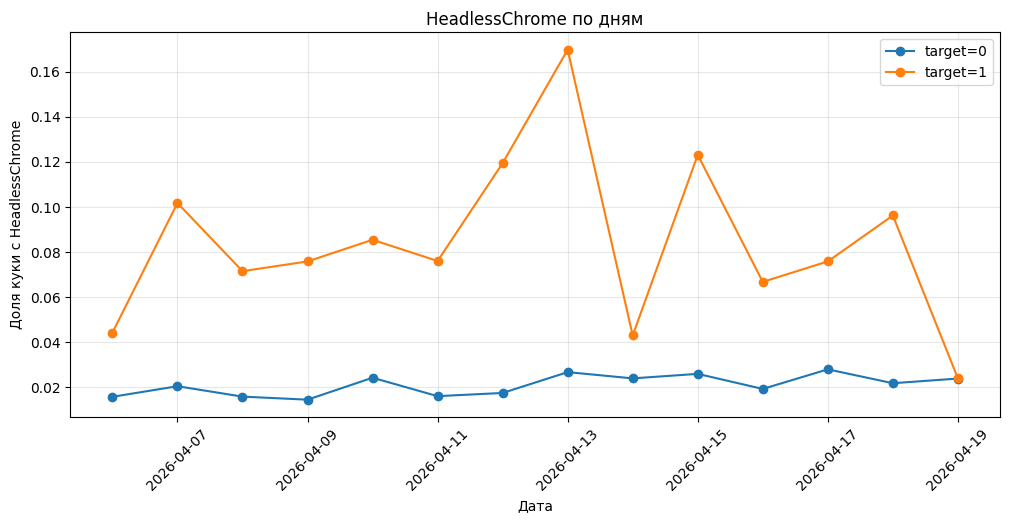

In [65]:
plt.figure(figsize=(12, 5))
plt.plot(headless_by_day.index, headless_by_day["human_headless_share"], marker="o", label="target=0")
plt.plot(headless_by_day.index, headless_by_day["bot_headless_share"], marker="o", label="target=1")
plt.xlabel("Дата")
plt.ylabel("Доля куки с HeadlessChrome")
plt.title("HeadlessChrome по дням")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Шестой блок — поведение указателя

In [66]:
pointer_events = ev_train[["cookie_id", "event_ts", "event_name", "platform", "pointer_x", "pointer_y"]].copy()
pointer_events["platform_norm"] = pointer_events["platform"].astype("string").str.strip().str.lower()
pointer_events["has_pointer"] = pointer_events["pointer_x"].notna() & pointer_events["pointer_y"].notna()

pointer_events_target = pointer_events.merge(train[["cookie_id", "target"]], on="cookie_id", how="left")

print("Всего событий:", len(pointer_events_target))
print("Событий с координатами:", pointer_events_target["has_pointer"].sum())
print("Доля событий с координатами:", pointer_events_target["has_pointer"].mean())

Всего событий: 198436
Событий с координатами: 66243
Доля событий с координатами: 0.333825515531456


Посмотрим, для каких типов событий вообще существуют координаты

In [67]:
pointer_by_event = pointer_events_target.groupby(["event_name", "target"])["has_pointer"].mean().unstack(fill_value=0)
pointer_by_event.columns = ["human_pointer_share", "bot_pointer_share"]

pointer_by_event

,human_pointer_share,bot_pointer_share
event_name,,
contact_chat_open,0.331962,0.151596
contact_message_sent,0.345958,0.147619
contact_phone_show,0.347587,0.132847
favorite_add,0.353892,0.308333
item_view,0.344878,0.248012
login,0.362036,0.285024
photo_swipe,0.347684,0.284946
search_results_view,0.346762,0.247049
seller_page_view,0.359233,0.229047


Тоже самое по платформам

In [68]:
pointer_by_platform = pointer_events_target.groupby(["platform_norm", "target"])["has_pointer"].mean().unstack(fill_value=0)
pointer_by_platform.columns = ["human_pointer_share", "bot_pointer_share"]

pointer_by_platform

,human_pointer_share,bot_pointer_share
platform_norm,,
android,0.000000,0.000000
desktop,0.662085,0.327211
ios,0.000000,0.000000
iphone,0.000000,0.000000
web,0.661554,0.331117


И посмотрим доступность указателя на уровне куки

In [69]:
pointer_cookie = pointer_events_target.groupby(["cookie_id", "target"]).agg(n_events=("event_name", "size"), pointer_event_count=("has_pointer", "sum"), pointer_event_share=("has_pointer", "mean")).reset_index()

pointer_cookie["has_any_pointer"] = pointer_cookie["pointer_event_count"] > 0

pointer_cookie.groupby("target")[["pointer_event_count", "pointer_event_share"]].mean().T

target,0,1
pointer_event_count,5.859890,7.251390
pointer_event_share,0.353566,0.265259


In [70]:
pointer_cookie.groupby("target")["has_any_pointer"].mean()

target
0    0.372351
1    0.279199
Name: has_any_pointer, dtype: float64

Теперь только события, где обе координаты присутствуют

In [71]:
pointer_valid = pointer_events_target[pointer_events_target["has_pointer"]].copy()

print("Событий людей:", (pointer_valid["target"] == 0).sum())
print("Событий ботов:", (pointer_valid["target"] == 1).sum())

Событий людей: 59724
Событий ботов: 6519


Посмотрим диапазоны координат

In [72]:
pointer_valid.groupby("target")[["pointer_x", "pointer_y"]].describe()

pointer_x                                                            \
           count        mean        std  min    25%    50%     75%     max   
target                                                                       
0        59724.0  956.386210  554.32095  0.0  477.0  954.0  1438.0  1919.0   
1         6519.0  685.554226  363.15854  0.0  394.0  668.0   952.5  1920.0   

       pointer_y                                                            
           count        mean         std  min    25%    50%    75%     max  
target                                                                      
0        59724.0  541.361212  310.541790  0.0  274.0  542.0  809.0  1080.0  
1         6519.0  507.083755  259.372988  0.0  326.0  497.0  693.0  1080.0

In [73]:
pointer_coord_features = pointer_valid.groupby("cookie_id").agg(pointer_count=("event_ts", "size"), pointer_x_mean=("pointer_x", "mean"), pointer_x_std=("pointer_x", "std"), pointer_x_min=("pointer_x", "min"), pointer_x_max=("pointer_x", "max"), pointer_y_mean=("pointer_y", "mean"), pointer_y_std=("pointer_y", "std"), pointer_y_min=("pointer_y", "min"), pointer_y_max=("pointer_y", "max")).reset_index()

pointer_coord_features["pointer_x_range"] = pointer_coord_features["pointer_x_max"] - pointer_coord_features["pointer_x_min"]
pointer_coord_features["pointer_y_range"] = pointer_coord_features["pointer_y_max"] - pointer_coord_features["pointer_y_min"]

pointer_coord_train = train[["cookie_id", "target"]].merge(pointer_coord_features, on="cookie_id", how="left")

Сравним вариативность и диапазон

In [74]:
pointer_coord_cols = ["pointer_count", "pointer_x_std", "pointer_y_std", "pointer_x_range", "pointer_y_range"]

pointer_coord_medians = pointer_coord_train.groupby("target")[pointer_coord_cols].median().T
pointer_coord_medians.columns = ["human_median", "bot_median"]

pointer_coord_medians

,human_median,bot_median
pointer_count,11.000000,19.000000
pointer_x_std,552.050024,200.551441
pointer_y_std,308.072691,200.969948
pointer_x_range,1632.000000,719.000000
pointer_y_range,914.000000,672.000000


И среднее

In [75]:
pointer_coord_means = pointer_coord_train.groupby("target")[pointer_coord_cols].mean().T
pointer_coord_means.columns = ["human_mean", "bot_mean"]

pointer_coord_means

,human_mean,bot_mean
pointer_count,15.737549,25.972112
pointer_x_std,540.923594,219.609624
pointer_y_std,300.348909,200.276529
pointer_x_range,1457.265349,738.390438
pointer_y_range,813.626087,654.446215


Ещё очень интересна повторяемость одних и тех же координат

In [76]:
pointer_pairs = pointer_valid.drop_duplicates(["cookie_id", "pointer_x", "pointer_y"]).groupby("cookie_id").size().rename("pointer_pair_nunique").reset_index()

pointer_repeat = pointer_valid.groupby("cookie_id").size().rename("pointer_count").reset_index()
pointer_repeat = pointer_repeat.merge(pointer_pairs, on="cookie_id", how="left")

pointer_repeat["pointer_unique_ratio"] = pointer_repeat["pointer_pair_nunique"] / pointer_repeat["pointer_count"]

pointer_repeat_train = train[["cookie_id", "target"]].merge(pointer_repeat, on="cookie_id", how="left")

pointer_repeat_train.groupby("target")["pointer_unique_ratio"].describe()

,count,mean,std,min,25%,50%,75%,max
target,,,,,,,,
0,3795.0,0.987210,0.035558,0.5,1.000000,1.0,1.0,1.0
1,251.0,0.985221,0.029129,0.8,0.976744,1.0,1.0,1.0


Визуализируем

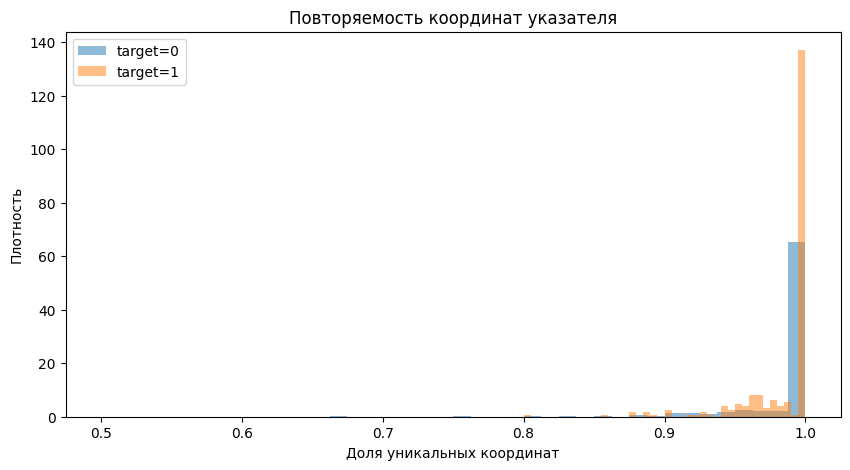

In [77]:
plt.figure(figsize=(10, 5))

for target in [0, 1]:
    values = pointer_repeat_train.loc[pointer_repeat_train["target"] == target, "pointer_unique_ratio"].dropna()
    plt.hist(values, bins=40, alpha=0.5, density=True, label=f"target={target}")

plt.xlabel("Доля уникальных координат")
plt.ylabel("Плотность")
plt.title("Повторяемость координат указателя")
plt.legend()
plt.show()

Разброс координат у ботов заметно ниже, поэтому дополнительно рассмотрим расстояния между координатами последовательных событий. Это позволит оценить не только область активности указателя, но и характер его перемещения между действиями

In [78]:
pointer_moves = pointer_valid[["cookie_id", "event_ts", "pointer_x", "pointer_y", "target"]].copy()
pointer_moves = pointer_moves.sort_values(["cookie_id", "event_ts"])

pointer_moves["prev_x"] = pointer_moves.groupby("cookie_id")["pointer_x"].shift()
pointer_moves["prev_y"] = pointer_moves.groupby("cookie_id")["pointer_y"].shift()

pointer_moves["dx"] = pointer_moves["pointer_x"] - pointer_moves["prev_x"]
pointer_moves["dy"] = pointer_moves["pointer_y"] - pointer_moves["prev_y"]
pointer_moves["move_distance"] = np.sqrt(pointer_moves["dx"] ** 2 + pointer_moves["dy"] ** 2)

Агрегируем

In [79]:
pointer_move_features = pointer_moves.groupby("cookie_id").agg(move_distance_mean=("move_distance", "mean"), move_distance_median=("move_distance", "median"), move_distance_std=("move_distance", "std"), move_distance_max=("move_distance", "max")).reset_index()

pointer_move_train = train[["cookie_id", "target"]].merge(pointer_move_features, on="cookie_id", how="left")

Медианы

In [80]:
pointer_move_medians = pointer_move_train.groupby("target")[["move_distance_mean", "move_distance_median", "move_distance_std", "move_distance_max"]].median().T
pointer_move_medians.columns = ["human_median", "bot_median"]

pointer_move_medians

,human_median,bot_median
move_distance_mean,778.667546,360.073461
move_distance_median,746.168195,349.235406
move_distance_std,408.076526,182.681200
move_distance_max,1485.531714,722.848808


Средние

In [81]:
pointer_move_means = pointer_move_train.groupby("target")[["move_distance_mean", "move_distance_median", "move_distance_std", "move_distance_max"]].mean().T
pointer_move_means.columns = ["human_mean", "bot_mean"]

pointer_move_means

,human_mean,bot_mean
move_distance_mean,787.605118,374.915328
move_distance_median,762.561216,364.001692
move_distance_std,399.108577,188.284233
move_distance_max,1414.584853,728.493723


И визуализируем медианное перемещение

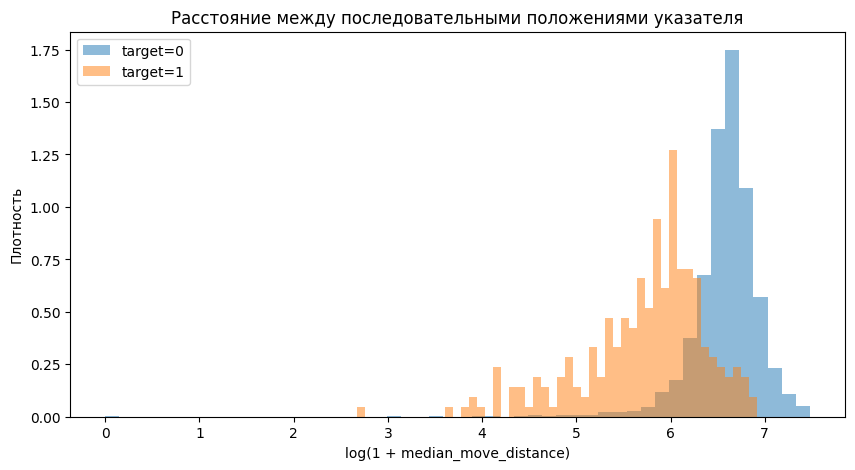

In [82]:
plt.figure(figsize=(10, 5))

for target in [0, 1]:
    values = np.log1p(pointer_move_train.loc[pointer_move_train["target"] == target, "move_distance_median"].dropna())
    plt.hist(values, bins=50, alpha=0.5, density=True, label=f"target={target}")

plt.xlabel("log(1 + median_move_distance)")
plt.ylabel("Плотность")
plt.title("Расстояние между последовательными положениями указателя")
plt.legend()
plt.show()

Ещё я бы посмотрел распределение самих координат визуально

На первом графике для людей, на втором для ботов

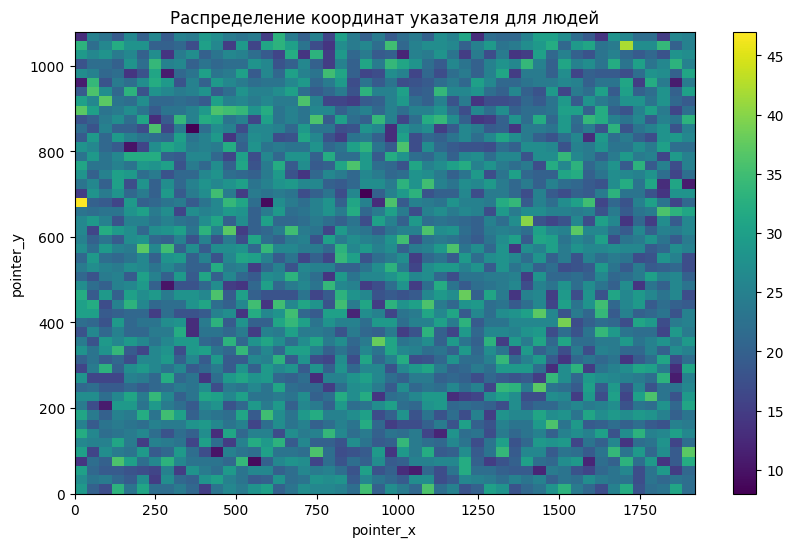

In [84]:
human_pointer = pointer_valid[pointer_valid["target"] == 0]

plt.figure(figsize=(10, 6))
plt.hist2d(human_pointer["pointer_x"], human_pointer["pointer_y"], bins=50)
plt.xlabel("pointer_x")
plt.ylabel("pointer_y")
plt.title("Распределение координат указателя для людей")
plt.colorbar()
plt.show()

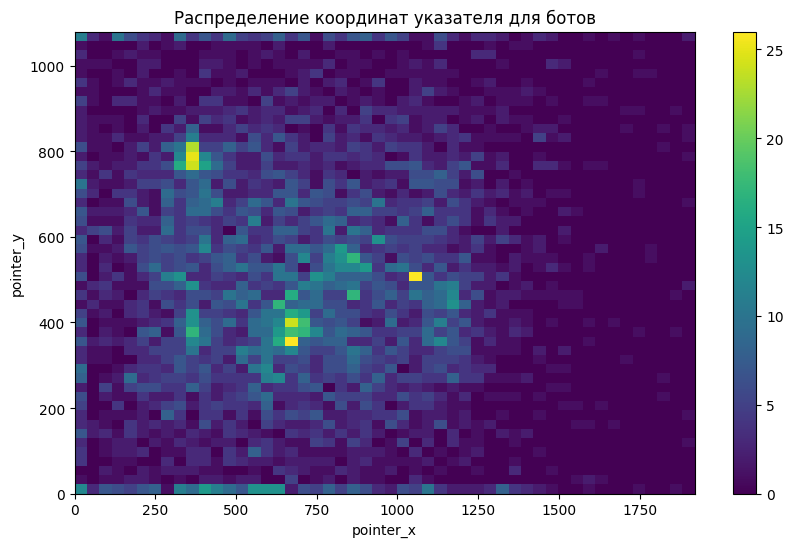

In [85]:
bot_pointer = pointer_valid[pointer_valid["target"] == 1]

plt.figure(figsize=(10, 6))
plt.hist2d(bot_pointer["pointer_x"], bot_pointer["pointer_y"], bins=50)
plt.xlabel("pointer_x")
plt.ylabel("pointer_y")
plt.title("Распределение координат указателя для ботов")
plt.colorbar()
plt.show()

Поскольку наличие координат зависит от платформы, дополнительно проверим, сохраняется ли различие в характеристиках указателя отдельно для web и desktop. Это позволит отделить собственно поведенческий сигнал от различий в составе платформ

In [86]:
pointer_platform_features = pointer_valid.groupby(["cookie_id", "platform_norm"]).agg(pointer_count=("event_ts", "size"), pointer_x_std=("pointer_x", "std"), pointer_y_std=("pointer_y", "std"), pointer_x_min=("pointer_x", "min"), pointer_x_max=("pointer_x", "max"), pointer_y_min=("pointer_y", "min"), pointer_y_max=("pointer_y", "max")).reset_index()

pointer_platform_features["pointer_x_range"] = pointer_platform_features["pointer_x_max"] - pointer_platform_features["pointer_x_min"]
pointer_platform_features["pointer_y_range"] = pointer_platform_features["pointer_y_max"] - pointer_platform_features["pointer_y_min"]

pointer_platform_features = pointer_platform_features.merge(train[["cookie_id", "target"]], on="cookie_id", how="left")

In [87]:
pointer_platform_cols = ["pointer_count", "pointer_x_std", "pointer_y_std", "pointer_x_range", "pointer_y_range"]

pointer_platform_medians = pointer_platform_features.groupby(["platform_norm", "target"])[pointer_platform_cols].median()

pointer_platform_medians

pointer_count  pointer_x_std  pointer_y_std  \
platform_norm target                                                
desktop       0                 3.0     530.749211     287.435717   
              1                 5.0     167.429814     179.249664   
web           0                 8.0     548.222309     307.052656   
              1                14.0     199.614397     195.113746   

                      pointer_x_range  pointer_y_range  
platform_norm target                                    
desktop       0                1000.0            537.0  
              1                 366.0            340.0  
web           0                1539.0            862.0  
              1                 656.0            611.0

То же самое для расстояний

In [88]:
pointer_moves_platform = pointer_valid[["cookie_id", "event_ts", "platform_norm", "pointer_x", "pointer_y", "target"]].copy()
pointer_moves_platform = pointer_moves_platform.sort_values(["cookie_id", "platform_norm", "event_ts"])

pointer_moves_platform["prev_x"] = pointer_moves_platform.groupby(["cookie_id", "platform_norm"])["pointer_x"].shift()
pointer_moves_platform["prev_y"] = pointer_moves_platform.groupby(["cookie_id", "platform_norm"])["pointer_y"].shift()

pointer_moves_platform["dx"] = pointer_moves_platform["pointer_x"] - pointer_moves_platform["prev_x"]
pointer_moves_platform["dy"] = pointer_moves_platform["pointer_y"] - pointer_moves_platform["prev_y"]
pointer_moves_platform["move_distance"] = np.sqrt(pointer_moves_platform["dx"] ** 2 + pointer_moves_platform["dy"] ** 2)

In [89]:
pointer_move_platform = pointer_moves_platform.groupby(["cookie_id", "platform_norm", "target"]).agg(move_distance_median=("move_distance", "median"), move_distance_mean=("move_distance", "mean")).reset_index()

pointer_move_platform.groupby(["platform_norm", "target"])[["move_distance_median", "move_distance_mean"]].median()

move_distance_median  move_distance_mean
platform_norm target                                          
desktop       0                 750.623246          773.406023
              1                 318.661644          337.708005
web           0                 748.159242          781.589373
              1                 340.060336          350.874293

# Седьмой блок про последовательности событий

До этого события рассматривались преимущественно независимо друг от друга. Однако автоматизированный сценарий может отличаться не только частотой действий, но и их порядком. Поэтому рассмотрим переходы между последовательными типами событий внутри каждой куки

Сначала формируем переходы

In [90]:
sequence_events = ev_train[["cookie_id", "event_ts", "event_name"]].copy()
sequence_events = sequence_events.sort_values(["cookie_id", "event_ts"])

sequence_events["next_event"] = sequence_events.groupby("cookie_id")["event_name"].shift(-1)
sequence_events["transition"] = sequence_events["event_name"] + " -> " + sequence_events["next_event"]

sequence_events = sequence_events.dropna(subset=["next_event"])
sequence_events = sequence_events.merge(train[["cookie_id", "target"]], on="cookie_id", how="left")

Сначала просто узнаем, какие переходы наиболее частые

In [91]:
sequence_events["transition"].value_counts().head(20)

transition
item_view -> item_view                        27340
search_results_view -> item_view              21806
item_view -> search_results_view              21732
search_results_view -> search_results_view    18915
item_view -> photo_swipe                       7899
photo_swipe -> item_view                       7676
photo_swipe -> search_results_view             6580
search_results_view -> photo_swipe             6431
favorite_add -> item_view                      4063
item_view -> favorite_add                      3971
seller_page_view -> item_view                  3754
item_view -> seller_page_view                  3731
search_results_view -> favorite_add            3393
favorite_add -> search_results_view            3346
seller_page_view -> search_results_view        3062
search_results_view -> seller_page_view        3044
photo_swipe -> photo_swipe                     2855
contact_phone_show -> item_view                2403
item_view -> contact_phone_show                2334
s

Теперь сравним структуру переходов людей и ботов

In [92]:
transition_counts = sequence_events.groupby(["transition", "target"]).size().unstack(fill_value=0)
transition_counts.columns = ["human_count", "bot_count"]

transition_counts["human_share"] = transition_counts["human_count"] / transition_counts["human_count"].sum()
transition_counts["bot_share"] = transition_counts["bot_count"] / transition_counts["bot_count"].sum()
transition_counts["share_diff"] = transition_counts["bot_share"] - transition_counts["human_share"]

transition_counts.sort_values("share_diff", ascending=False).head(20)

,human_count,bot_count,human_share,bot_share,share_diff
transition,,,,,
item_view -> item_view,22282,5058,0.137767,0.197516,0.059750
item_view -> search_results_view,17832,3900,0.110253,0.152296,0.042043
search_results_view -> item_view,17905,3901,0.110704,0.152335,0.041631
search_results_view -> search_results_view,15525,3390,0.095989,0.132381,0.036391
item_view -> seller_page_view,3083,648,0.019062,0.025305,0.006243
seller_page_view -> item_view,3107,647,0.019210,0.025266,0.006055
search_results_view -> seller_page_view,2535,509,0.015674,0.019877,0.004203
seller_page_view -> search_results_view,2557,505,0.015810,0.019720,0.003911
seller_page_view -> seller_page_view,530,122,0.003277,0.004764,0.001487


И в обратную сторону

In [93]:
transition_counts.sort_values("share_diff").head(20)

,human_count,bot_count,human_share,bot_share,share_diff
transition,,,,,
photo_swipe -> item_view,6942,734,0.042922,0.028663,-0.014259
item_view -> photo_swipe,7122,777,0.044034,0.030342,-0.013692
photo_swipe -> search_results_view,5977,603,0.036955,0.023547,-0.013408
search_results_view -> photo_swipe,5843,588,0.036127,0.022962,-0.013165
item_view -> favorite_add,3686,285,0.022790,0.011129,-0.011661
favorite_add -> search_results_view,3137,209,0.019396,0.008162,-0.011234
favorite_add -> item_view,3748,315,0.023173,0.012301,-0.010873
search_results_view -> favorite_add,3162,231,0.019550,0.009021,-0.010530
photo_swipe -> photo_swipe,2672,183,0.016521,0.007146,-0.009374


Далее повтор одного и того же типа события подряд

In [94]:
sequence_events["same_event_transition"] = sequence_events["event_name"] == sequence_events["next_event"]

same_transition_cookie = sequence_events.groupby("cookie_id")["same_event_transition"].mean().rename("same_event_transition_share").reset_index()
same_transition_cookie = train[["cookie_id", "target"]].merge(same_transition_cookie, on="cookie_id", how="left")

same_transition_cookie.groupby("target")["same_event_transition_share"].describe()

,count,mean,std,min,25%,50%,75%,max
target,,,,,,,,
0,9949.0,0.264920,0.188630,0.0,0.153846,0.250000,0.350000,1.0
1,895.0,0.326485,0.169462,0.0,0.222222,0.328947,0.421053,1.0


И визуализируем

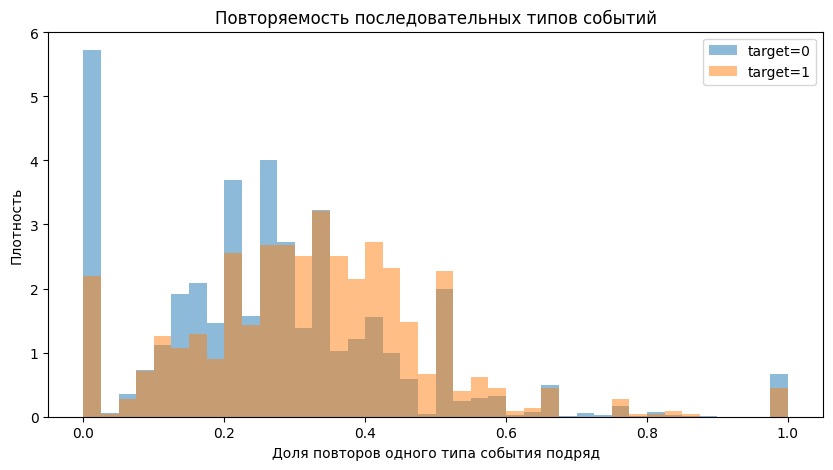

In [95]:
plt.figure(figsize=(10, 5))

for target in [0, 1]:
    values = same_transition_cookie.loc[same_transition_cookie["target"] == target, "same_event_transition_share"].dropna()
    plt.hist(values, bins=40, alpha=0.5, density=True, label=f"target={target}")

plt.xlabel("Доля повторов одного типа события подряд")
plt.ylabel("Плотность")
plt.title("Повторяемость последовательных типов событий")
plt.legend()
plt.show()

Ещё посмотрим, насколько разнообразны переходы внутри одной куки

In [96]:
transition_diversity = sequence_events.groupby("cookie_id").agg(transition_count=("transition", "size"), transition_nunique=("transition", "nunique")).reset_index()

transition_diversity["transition_unique_ratio"] = transition_diversity["transition_nunique"] / transition_diversity["transition_count"]

transition_diversity_train = train[["cookie_id", "target"]].merge(transition_diversity, on="cookie_id", how="left")

transition_diversity_train.groupby("target")[["transition_count", "transition_nunique", "transition_unique_ratio"]].median().T

target,0,1
transition_count,11.000000,19.00000
transition_nunique,8.000000,10.00000
transition_unique_ratio,0.727273,0.53125


Самое заметное по этим данным - у ботов значительно чаще идут подряд или чередуются два основных типа действий
- item_view - item_view: 19.75% против 13.78%
- search_results_view - search_results_view: 13.24% против 9.60%
- item_view - search_results_view: 15.23% против 11.03%
- search_results_view - item_view: 15.23% против 11.07%

При этом человеческий трафик чаще включает photo_swipe, favorite_add, login, контактные действия. Это уже выглядит логично, автоматизированный сценарий сильнее концентрируется на выдаче и объявлениях, а человек чаще совершает дополнительные интерфейсные действия.

Дополнительно рассмотрим длины непрерывных серий одинаковых событий. Более длинные серии могут быть характерны для автоматизированного сценария, который последовательно выполняет однотипные действия.

In [97]:
run_events = ev_train[["cookie_id", "event_ts", "event_name"]].copy()
run_events = run_events.sort_values(["cookie_id", "event_ts"])
run_events["new_run"] = run_events["event_name"] != run_events.groupby("cookie_id")["event_name"].shift()
run_events["run_id"] = run_events.groupby("cookie_id")["new_run"].cumsum()

In [98]:
run_lengths = run_events.groupby(["cookie_id", "run_id", "event_name"]).size().rename("run_length").reset_index()

Общая длина серий

In [99]:
run_summary = run_lengths.groupby("cookie_id")["run_length"].agg(["mean", "max"]).reset_index()
run_summary.columns = ["cookie_id", "run_length_mean", "run_length_max"]

run_summary_train = train[["cookie_id", "target"]].merge(run_summary, on="cookie_id", how="left")

run_summary_train.groupby("target")[["run_length_mean", "run_length_max"]].describe()

run_length_mean                                                         \
                 count      mean       std  min       25%       50%       75%   
target                                                                          
0              10192.0  1.359509  0.371016  1.0  1.142857  1.296296  1.500000   
1                899.0  1.518272  0.488320  1.0  1.250000  1.451613  1.666667   

            run_length_max                                                
        max          count      mean       std  min  25%  50%  75%   max  
target                                                                    
0       9.0        10192.0  2.696527  1.304354  1.0  2.0  2.0  3.0  12.0  
1       7.0          899.0  3.677419  1.747557  1.0  2.0  3.0  5.0  13.0

Теперь отдельно максимальные серии для основных событий

In [100]:
run_event_max = run_lengths.pivot_table(index="cookie_id", columns="event_name", values="run_length", aggfunc="max", fill_value=0)
run_event_max = run_event_max.add_prefix("max_run_").reset_index()
run_event_max_train = train[["cookie_id", "target"]].merge(run_event_max, on="cookie_id", how="left")

In [101]:
run_cols = ["max_run_item_view", "max_run_search_results_view", "max_run_photo_swipe", "max_run_favorite_add"]

run_event_max_train.groupby("target")[run_cols].median().T

target,0,1
max_run_item_view,2.0,3.0
max_run_search_results_view,2.0,2.0
max_run_photo_swipe,1.0,1.0
max_run_favorite_add,1.0,0.0


И средние

In [102]:
run_event_max_train.groupby("target")[run_cols].mean().T

target,0,1
max_run_item_view,2.200157,3.187987
max_run_search_results_view,1.870192,2.578420
max_run_photo_swipe,0.951236,0.912125
max_run_favorite_add,0.629023,0.488320


Далее оч интересная проверка - разнообразие типов событий через энтропию. Если бот в основном повторяет item_view и search_results_view, энтропия распределения событий может быть ниже

In [103]:
event_distribution = ev_train.groupby(["cookie_id", "event_name"]).size().rename("event_count").reset_index()
event_distribution["total_events"] = event_distribution.groupby("cookie_id")["event_count"].transform("sum")
event_distribution["event_prob"] = event_distribution["event_count"] / event_distribution["total_events"]
event_distribution["entropy_component"] = -event_distribution["event_prob"] * np.log(event_distribution["event_prob"])

In [104]:
event_entropy = event_distribution.groupby("cookie_id")["entropy_component"].sum().rename("event_entropy").reset_index()
event_nunique = event_distribution.groupby("cookie_id").size().rename("event_type_nunique").reset_index()

event_entropy = event_entropy.merge(event_nunique, on="cookie_id", how="left")
event_entropy["normalized_event_entropy"] = np.where(event_entropy["event_type_nunique"] > 1, event_entropy["event_entropy"] / np.log(event_entropy["event_type_nunique"]), 0)

In [105]:
event_entropy_train = train[["cookie_id", "target"]].merge(event_entropy, on="cookie_id", how="left")

event_entropy_train.groupby("target")[["event_entropy", "event_type_nunique", "normalized_event_entropy"]].describe()

event_entropy                                                         \
               count      mean       std  min       25%       50%       75%   
target                                                                        
0            10192.0  1.218762  0.405368  0.0  1.037054  1.305704  1.504788   
1              899.0  1.195239  0.319937  0.0  1.033715  1.211538  1.398624   

                 event_type_nunique            ...            \
             max              count      mean  ...  75%  max   
target                                         ...             
0       2.100679            10192.0  4.598312  ...  6.0  9.0   
1       1.958277              899.0  4.803115  ...  6.0  9.0   

       normalized_event_entropy                                               \
                          count      mean       std  min       25%       50%   
target                                                                         
0                       10192.0  0.832079  0.189066  0.0  0.802699  0.866865   
1                         899.0  0.793175  0.144232  0.0  0.722947  0.807165   

                       
             75%  max  
target                 
0       0.923220  1.0  
1       0.881916  1.0  

[2 rows x 24 columns]

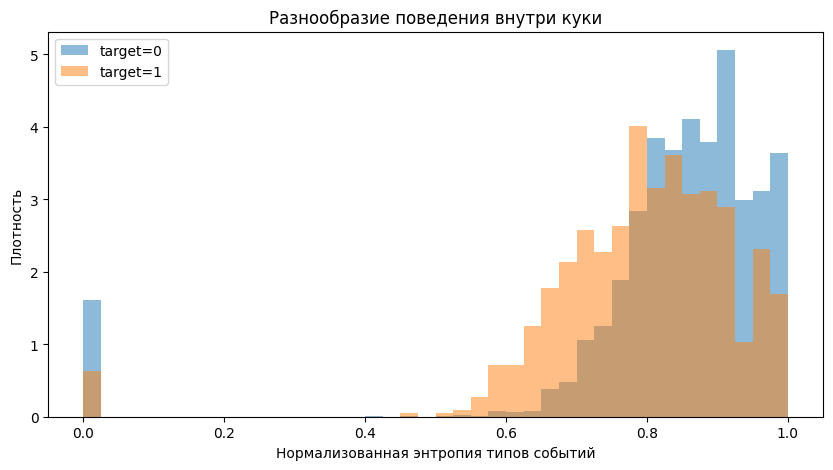

In [106]:
plt.figure(figsize=(10, 5))

for target in [0, 1]:
    values = event_entropy_train.loc[event_entropy_train["target"] == target, "normalized_event_entropy"].dropna()
    plt.hist(values, bins=40, alpha=0.5, density=True, label=f"target={target}")

plt.xlabel("Нормализованная энтропия типов событий")
plt.ylabel("Плотность")
plt.title("Разнообразие поведения внутри куки")
plt.legend()
plt.show()

Средняя длина серии одинаковых событий у ботов выше: 1.52 против 1.36, а максимальная серия в среднем 3.68 против 2.70. Особенно хорошо это видно для item_view: средний максимум серии 3.19 у ботов против 2.20 у людей. Для search_results_view тоже есть разница: 2.58 против 1.87.


Энтропия тоже подтверждает картину. Нормализованная энтропия: 0.867 у людей против 0.807  у ботов по медиане
При этом число различных типов событий у ботов не меньше. Это важная деталь: бот может использовать сопоставимое количество типов действий, но распределяет активность между ними менее равномерно, основные действия доминируют сильнее.

# Восьмой блок про возраст куки

До этого анализировалось преимущественно поведение внутри окна наблюдения. Однако в исходных метаданных также известно время первого появления куки. Проверим, отличается ли возраст куки к началу окна между человеческим и автоматизированным трафиком.

Сначала возраст

In [107]:
cookie_meta = train[["cookie_id", "cookie_created_at", "window_start_ts", "window_end_ts", "target"]].copy()

cookie_meta["cookie_age_sec"] = (cookie_meta["window_start_ts"] - cookie_meta["cookie_created_at"]).dt.total_seconds()
cookie_meta["cookie_age_hours"] = cookie_meta["cookie_age_sec"] / 3600
cookie_meta["cookie_age_days"] = cookie_meta["cookie_age_sec"] / 86400

cookie_meta.groupby("target")[["cookie_age_hours", "cookie_age_days"]].describe(percentiles=[0.5, 0.75, 0.9, 0.95, 0.99])

cookie_age_hours                                                   \
                  count         mean          std       min          50%   
target                                                                     
0               10192.0  1773.801448  1607.303160  0.348056  1482.776806   
1                 899.0  1169.433860  1507.096739  0.296667   455.241667   

                                                                          \
                75%          90%          95%          99%           max   
target                                                                     
0       2650.713611  3926.469667  4862.545528  6799.727222  10782.836944   
1       2002.870556  3337.375000  4280.911444  5980.097300   8682.336111   

       cookie_age_days                                                        \
                 count       mean        std       min        50%        75%   
target                                                                         
0              10192.0  73.908394  66.970965  0.014502  61.782367  110.44640   
1                899.0  48.726411  62.795697  0.012361  18.968403   83.45294   

                                                        
               90%         95%         99%         max  
target                                                  
0       163.602903  202.606064  283.321968  449.284873  
1       139.057292  178.371310  249.170721  361.764005

Посмотрим распределение в логарифме

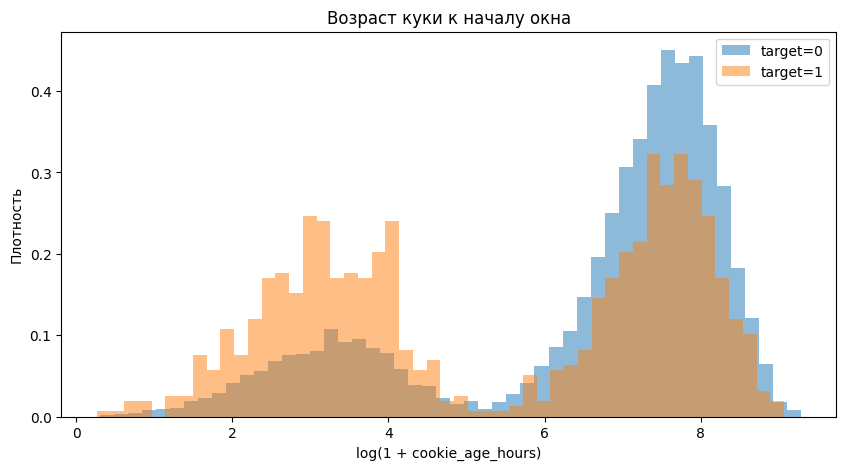

In [108]:
plt.figure(figsize=(10, 5))

for target in [0, 1]:
    values = np.log1p(cookie_meta.loc[cookie_meta["target"] == target, "cookie_age_hours"].clip(lower=0))
    plt.hist(values, bins=50, alpha=0.5, density=True, label=f"target={target}")

plt.xlabel("log(1 + cookie_age_hours)")
plt.ylabel("Плотность")
plt.title("Возраст куки к началу окна")
plt.legend()
plt.show()

Теперь отдельно очень молодые куки

In [109]:
cookie_meta["age_lt_1h"] = cookie_meta["cookie_age_hours"] < 1
cookie_meta["age_lt_6h"] = cookie_meta["cookie_age_hours"] < 6
cookie_meta["age_lt_24h"] = cookie_meta["cookie_age_hours"] < 24
cookie_meta["age_lt_3d"] = cookie_meta["cookie_age_days"] < 3
cookie_meta["age_lt_7d"] = cookie_meta["cookie_age_days"] < 7

In [110]:
age_flags = ["age_lt_1h", "age_lt_6h", "age_lt_24h", "age_lt_3d", "age_lt_7d"]

cookie_meta.groupby("target")[age_flags].mean().T

target,0,1
age_lt_1h,0.000981,0.003337
age_lt_6h,0.020114,0.052280
age_lt_24h,0.104297,0.259177
age_lt_3d,0.193583,0.448276
age_lt_7d,0.215757,0.481646


Ещё проверим, есть ли вообще странные случаи, когда куки формально появилась после начала окна

In [111]:
print("После начала окна:", (cookie_meta["cookie_age_sec"] < 0).sum())
print("Сразу:", (cookie_meta["cookie_age_sec"] == 0).sum())

После начала окна: 0
Сразу: 0


И здесь очень важно сразу посмотреть временную стабильность

In [112]:
cookie_age_by_day = cookie_meta.groupby(["window_start_ts", "target"])["cookie_age_days"].median().unstack()
cookie_age_by_day.columns = ["human_median_age", "bot_median_age"]

cookie_age_by_day

,human_median_age,bot_median_age
window_start_ts,,
2026-04-06,61.747101,2.372274
2026-04-07,58.229213,47.567014
2026-04-08,62.631811,38.251337
2026-04-09,66.013970,2.979936
2026-04-10,59.313252,25.661892
2026-04-11,58.953345,19.952975
2026-04-12,63.958571,2.083299
2026-04-13,62.692830,37.388623
2026-04-14,66.578073,3.070255


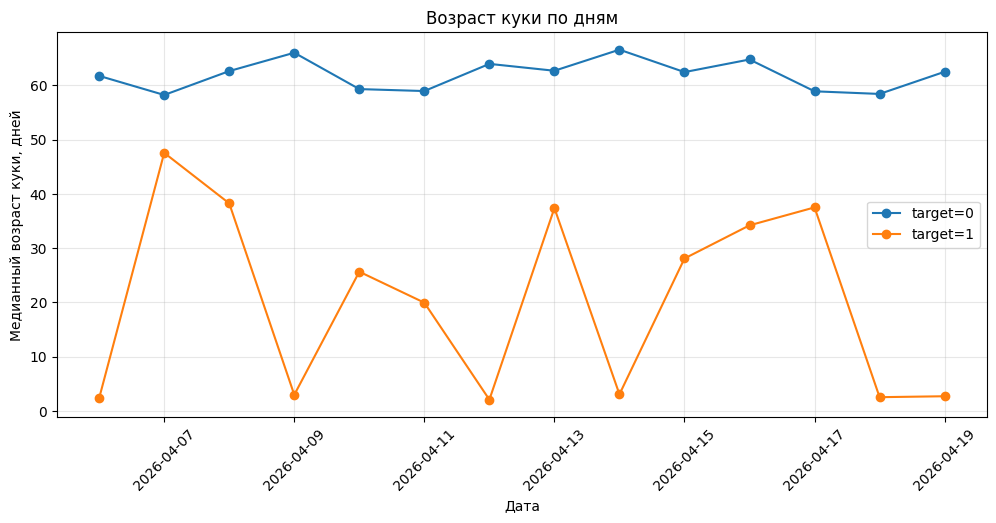

In [113]:
plt.figure(figsize=(12, 5))
plt.plot(cookie_age_by_day.index, cookie_age_by_day["human_median_age"], marker="o", label="target=0")
plt.plot(cookie_age_by_day.index, cookie_age_by_day["bot_median_age"], marker="o", label="target=1")
plt.xlabel("Дата")
plt.ylabel("Медианный возраст куки, дней")
plt.title("Возраст куки по дням")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Я бы еще сравнил распределение трейна и теста без таргета. Если распределение возраста сильно сдвинулось, этот признак может оказаться нестабильным

In [114]:
train_age = (train["window_start_ts"] - train["cookie_created_at"]).dt.total_seconds() / 86400
test_age = (test["window_start_ts"] - test["cookie_created_at"]).dt.total_seconds() / 86400

print("Медианный возраст на трейне:", train_age.median())
print("Медианный возраст на тесте:", test_age.median())
print("Средний возраст на трейне:", train_age.mean())
print("Средний возраст на тесте:", test_age.mean())

Медианный возраст на трейне: 59.75917824074074
Медианный возраст на тесте: 58.631076388888886
Средний возраст на трейне: 71.86722493755364
Средний возраст на тесте: 71.64703841630642


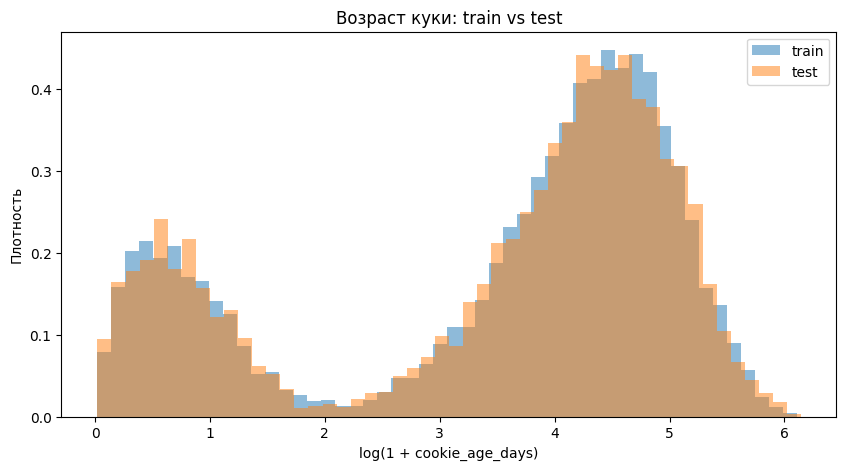

In [115]:
plt.figure(figsize=(10, 5))
plt.hist(np.log1p(train_age.clip(lower=0)), bins=50, alpha=0.5, density=True, label="train")
plt.hist(np.log1p(test_age.clip(lower=0)), bins=50, alpha=0.5, density=True, label="test")
plt.xlabel("log(1 + cookie_age_days)")
plt.ylabel("Плотность")
plt.title("Возраст куки: train vs test")
plt.legend()
plt.show()